# Seguimiento 4 — Exploración y Análisis de Datos (EAD) y Análisis de Clusters

**Proyecto:** SGRH — Sistema de Gestión de Recursos Humanos
**Base de datos:** AdventureWorks migrada a PostgreSQL (Supabase): esquemas `humanresources` y `person`

## Objetivo

1. Hacer el **EAD** de las tablas que usa el SGRH: estructura, calidad e integridad de los datos, análisis univariado, bivariado y temporal.
2. Construir un **dataset analítico a nivel de empleado** a partir de las tablas históricas.
3. Aplicar **análisis de clusters** (K-Means y clustering jerárquico) para encontrar perfiles de empleados y describirlos.

## Alcance: tablas analizadas

| Esquema | Tabla | Rol en el sistema |
|---|---|---|
| `humanresources` | `employee` | Entidad central: datos laborales del empleado |
| `humanresources` | `department` | Catálogo de departamentos |
| `humanresources` | `shift` | Catálogo de turnos |
| `humanresources` | `employeedepartmenthistory` | Histórico de asignaciones (departamento + turno) |
| `humanresources` | `employeepayhistory` | Histórico salarial (tarifa por hora) |
| `humanresources` | `jobcandidate` | Candidatos a contratar |
| `person` | `person` | Nombres y tipo de persona |
| `person` | `businessentity` | Identificador común de personas |

La tabla `app.app_user` queda **fuera** del análisis: guarda credenciales del sistema (hashes de contraseña) y no aporta información de RR. HH.

## Reglas de negocio que se respetan (las mismas que aplica la aplicación)

- **Salario vigente**: el registro de `employeepayhistory` con la `ratechangedate` más reciente.
- **Asignación vigente**: la fila de `employeedepartmenthistory` sin `enddate` (si hubiera varias, la de `startdate` más reciente).
- **Empleado activo**: `currentflag = true` (la baja es lógica).
- **Candidato contratado**: `jobcandidate.businessentityid` no nulo.
- **Antigüedad**: años cumplidos entre `hiredate` y la fecha actual, con los mismos tramos del reporte de antigüedad.

## 1. Configuración del entorno

Requisitos: `pip install -r analisis/requirements.txt`. La conexión se lee de la variable `DATABASE_URL` del archivo `.env` en la raíz del proyecto, la misma que usa la aplicación. **Todas las consultas son de solo lectura** (`SELECT`): el notebook no modifica la base.

In [1]:
import os
import re
import warnings
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from dotenv import load_dotenv
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_samples,
                             silhouette_score)
from sklearn.preprocessing import StandardScaler
from sqlalchemy import create_engine, text

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)

# Paleta categórica en orden fijo (azul, naranja, aqua, amarillo, magenta, verde, violeta, rojo)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
MARCADORES = ["o", "s", "^", "D", "v", "P", "X", "*"]  # codificación secundaria para >3 grupos
SECUENCIAL = "Blues"
DIVERGENTE = "RdBu_r"

sns.set_theme(style="whitegrid", context="notebook", palette=PALETA)
plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 100,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.color": "#e6e6e3",
    "axes.edgecolor": "#b5b4ad",
})

SEMILLA = 42
HOY = pd.Timestamp(date.today())

def eje_log(ax, eje="y"):
    # Escala logarítmica con marcas legibles (5, 10, 20, 50, 100...)
    getattr(ax, f"set_{eje}scale")("log")
    a = getattr(ax, f"{eje}axis")
    a.set_major_locator(mticker.LogLocator(base=10, subs=[1, 2, 5]))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    a.set_minor_formatter(mticker.NullFormatter())

def envolver(ax, eje="x", ancho=16):
    # Parte etiquetas largas en varias líneas para que no se superpongan
    import textwrap
    etiquetas = [textwrap.fill(t.get_text(), ancho) for t in getattr(ax, f"get_{eje}ticklabels")()]
    getattr(ax, f"set_{eje}ticks")(getattr(ax, f"get_{eje}ticks")())
    getattr(ax, f"set_{eje}ticklabels")(etiquetas)

## 2. Conexión y carga de las tablas

In [2]:
# Busca el .env subiendo desde el directorio actual (el notebook vive en analisis/)
for carpeta in [Path.cwd(), *Path.cwd().parents]:
    if (carpeta / ".env").exists():
        load_dotenv(carpeta / ".env")
        break

url = os.environ.get("DATABASE_URL")
if not url:
    raise RuntimeError("Falta DATABASE_URL: copia .env.example a .env y complétalo.")

# Prisma usa postgresql://...?schema=...; SQLAlchemy necesita el driver y no entiende ?schema
url = re.sub(r"^postgres(ql)?://", "postgresql+psycopg://", url).split("?")[0]
engine = create_engine(url, connect_args={"connect_timeout": 15})

CONSULTAS = {
    "employee": "SELECT * FROM humanresources.employee",
    "department": "SELECT * FROM humanresources.department",
    "shift": "SELECT * FROM humanresources.shift",
    "edh": "SELECT * FROM humanresources.employeedepartmenthistory",
    "eph": "SELECT * FROM humanresources.employeepayhistory",
    "jobcandidate": "SELECT * FROM humanresources.jobcandidate",
    "person": "SELECT * FROM person.person",
    "businessentity": "SELECT * FROM person.businessentity",
}

with engine.connect() as conn:
    conn.execute(text("SET TRANSACTION READ ONLY"))
    tablas = {nombre: pd.read_sql(sql, conn) for nombre, sql in CONSULTAS.items()}

pd.DataFrame({
    "tabla": list(tablas),
    "filas": [len(df) for df in tablas.values()],
    "columnas": [df.shape[1] for df in tablas.values()],
}).set_index("tabla")

,filas,columnas
tabla,,
employee,292,16
department,16,4
shift,3,5
edh,300,6
eph,319,5
jobcandidate,14,6
person,19974,13
businessentity,20779,3


In [3]:
# Atajos y tipos de fecha homogéneos (sin zona horaria) para operar con ellos
employee = tablas["employee"].copy()
department = tablas["department"].copy()
shift = tablas["shift"].copy()
edh = tablas["edh"].copy()
eph = tablas["eph"].copy()
jobcandidate = tablas["jobcandidate"].copy()
person = tablas["person"].copy()
businessentity = tablas["businessentity"].copy()

def sin_tz(serie):
    serie = pd.to_datetime(serie, utc=True)
    return serie.dt.tz_convert(None)

for df in [employee, department, shift, edh, eph, jobcandidate, person, businessentity]:
    df["modifieddate"] = sin_tz(df["modifieddate"])

employee["birthdate"] = pd.to_datetime(employee["birthdate"])
employee["hiredate"] = pd.to_datetime(employee["hiredate"])
edh["startdate"] = pd.to_datetime(edh["startdate"])
edh["enddate"] = pd.to_datetime(edh["enddate"])
eph["ratechangedate"] = sin_tz(eph["ratechangedate"])
eph["rate"] = eph["rate"].astype(float)

## 3. Estructura de los datos (diccionario)

Para cada tabla: tipo de dato, nulos, valores distintos y un ejemplo. Sirve para decidir qué variables son **numéricas**, **categóricas**, **fechas** o **identificadores/técnicas** (estas últimas no se analizan: `rowguid`, `organizationnode`, `modifieddate`).

In [4]:
def diccionario(df):
    return pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": (df.isna().mean() * 100).round(1),
        "distintos": df.nunique(),
        "ejemplo": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })

for nombre in ["employee", "eph", "edh"]:
    print(f"\n=== {nombre} ===")
    display(diccionario(tablas[nombre]))


=== employee ===


,tipo,nulos,% nulos,distintos,ejemplo
businessentityid,int64,0,0.00,292,2
nationalidnumber,str,0,0.00,292,245797967
loginid,str,0,0.00,292,adventure-works\terri0
organizationnode,str,3,1.00,289,#(88)
organizationlevel,float64,3,1.00,4,1.00
jobtitle,str,0,0.00,69,Vice President of Engineering
birthdate,object,0,0.00,277,1971-08-01
maritalstatus,str,0,0.00,2,S
gender,str,0,0.00,2,F
hiredate,object,0,0.00,166,2008-01-31



=== eph ===


,tipo,nulos,% nulos,distintos,ejemplo
businessentityid,int64,0,0.00,292,1
ratechangedate,"datetime64[us, UTC]",0,0.00,179,2009-01-14 00:00:00+00:00
rate,float64,0,0.00,69,125.50
payfrequency,int64,0,0.00,2,2
modifieddate,"datetime64[us, UTC]",0,0.00,29,2014-06-30 00:00:00+00:00



=== edh ===


,tipo,nulos,% nulos,distintos,ejemplo
businessentityid,int64,0,0.00,292,1
departmentid,int64,0,0.00,16,16
shiftid,int64,0,0.00,3,1
startdate,object,0,0.00,173,2009-01-14
enddate,object,292,97.30,8,2010-05-30
modifieddate,"datetime64[us, UTC]",0,0.00,175,2009-01-13 00:00:00+00:00


In [5]:
for nombre in ["department", "shift", "jobcandidate", "person"]:
    df = tablas[nombre]
    if nombre == "jobcandidate":
        df = df.assign(resume=df["resume"].str.slice(0, 40))
    if nombre == "person":
        df = df.drop(columns=["additionalcontactinfo", "demographics"])
    print(f"\n=== {nombre} ===")
    display(diccionario(df))


=== department ===


,tipo,nulos,% nulos,distintos,ejemplo
departmentid,int64,0,0.00,16,1
name,str,0,0.00,16,Engineering
groupname,str,0,0.00,6,Research and Development
modifieddate,"datetime64[us, UTC]",0,0.00,1,2008-04-30 00:00:00+00:00



=== shift ===


,tipo,nulos,% nulos,distintos,ejemplo
shiftid,int64,0,0.00,3,1
name,str,0,0.00,3,Day
starttime,object,0,0.00,3,07:00:00
endtime,object,0,0.00,3,15:00:00
modifieddate,"datetime64[us, UTC]",0,0.00,1,2008-04-30 00:00:00+00:00



=== jobcandidate ===


,tipo,nulos,% nulos,distintos,ejemplo
jobcandidateid,int64,0,0.00,14,3
businessentityid,float64,11,78.60,3,274.00
resume,str,0,0.00,2,"<ns:Resume xmlns:ns=""http://schemas.micr"
modifieddate,"datetime64[us, UTC]",0,0.00,5,2007-06-23 00:00:00+00:00
firstname,str,1,7.10,13,Krishna
lastname,str,1,7.10,13,Sunkammurali



=== person ===


,tipo,nulos,% nulos,distintos,ejemplo
businessentityid,int64,0,0.00,19974,2
persontype,str,0,0.00,6,EM
namestyle,bool,0,0.00,1,False
title,str,18964,94.90,7,Ms.
firstname,str,0,0.00,1019,Terri
middlename,str,8500,42.60,72,Lee
lastname,str,0,0.00,1207,Duffy
suffix,str,19921,99.70,6,III
emailpromotion,int64,0,0.00,3,1
rowguid,object,0,0.00,19974,d8763459-8aa8-47cc-aff7-c9079af79033


In [6]:
display(department.sort_values("departmentid"))
display(shift)

,departmentid,name,groupname,modifieddate
0,1,Engineering,Research and Development,2008-04-30
1,2,Tool Design,Research and Development,2008-04-30
2,3,Sales,Sales and Marketing,2008-04-30
3,4,Marketing,Sales and Marketing,2008-04-30
4,5,Purchasing,Inventory Management,2008-04-30
5,6,Research and Development,Research and Development,2008-04-30
6,7,Production,Manufacturing,2008-04-30
7,8,Production Control,Manufacturing,2008-04-30
8,9,Human Resources,Executive General and Administration,2008-04-30
9,10,Finance,Executive General and Administration,2008-04-30


,shiftid,name,starttime,endtime,modifieddate
0,1,Day,07:00:00,15:00:00,2008-04-30
1,2,Evening,15:00:00,23:00:00,2008-04-30
2,3,Night,23:00:00,07:00:00,2008-04-30


## 4. Calidad e integridad de los datos

Se revisan cinco aspectos:

1. **Valores nulos** en columnas relevantes.
2. **Duplicados** de la llave primaria.
3. **Integridad referencial** (las FK apuntan a filas que existen).
4. **Reglas de dominio** (valores permitidos, fechas coherentes).
5. **Reglas del negocio del SGRH** (cada empleado activo tiene exactamente una asignación vigente y al menos un salario).

In [7]:
# 4.1 Nulos por tabla (solo columnas con algún nulo)
nulos = []
for nombre, df in tablas.items():
    for col, n in df.isna().sum().items():
        if n > 0:
            nulos.append({"tabla": nombre, "columna": col, "nulos": n, "% nulos": round(n / len(df) * 100, 1)})
pd.DataFrame(nulos).sort_values(["tabla", "% nulos"], ascending=[True, False])

,tabla,columna,nulos,% nulos
2,edh,enddate,292,97.30
0,employee,organizationnode,3,1.00
1,employee,organizationlevel,3,1.00
3,jobcandidate,businessentityid,11,78.60
4,jobcandidate,firstname,1,7.10
5,jobcandidate,lastname,1,7.10
9,person,additionalcontactinfo,19964,99.90
8,person,suffix,19921,99.70
6,person,title,18964,94.90
7,person,middlename,8500,42.60


Los nulos esperables por diseño son: `person.title`, `middlename` y `suffix` (opcionales), `edh.enddate` (nulo = asignación **vigente**), `jobcandidate.businessentityid` (nulo = candidato **pendiente**) y `employee.organizationnode/organizationlevel` (jerarquía heredada de SQL Server que no se usa). Ninguno es un error de datos; en cada caso el nulo tiene significado.

In [8]:
# 4.2 Duplicados de llave primaria
llaves = {
    "employee": ["businessentityid"],
    "department": ["departmentid"],
    "shift": ["shiftid"],
    "edh": ["businessentityid", "startdate", "departmentid", "shiftid"],
    "eph": ["businessentityid", "ratechangedate"],
    "jobcandidate": ["jobcandidateid"],
    "person": ["businessentityid"],
    "businessentity": ["businessentityid"],
}
pd.Series({t: tablas[t].duplicated(subset=k).sum() for t, k in llaves.items()}, name="PK duplicadas").to_frame()

,PK duplicadas
employee,0
department,0
shift,0
edh,0
eph,0
jobcandidate,0
person,0
businessentity,0


In [9]:
# 4.3 Integridad referencial: filas hijas cuya FK no existe en la tabla padre
def huerfanos(hija, col_h, padre, col_p):
    return int((~hija[col_h].dropna().isin(padre[col_p])).sum())

pd.DataFrame([
    ("employee → person", huerfanos(employee, "businessentityid", person, "businessentityid")),
    ("person → businessentity", huerfanos(person, "businessentityid", businessentity, "businessentityid")),
    ("edh → employee", huerfanos(edh, "businessentityid", employee, "businessentityid")),
    ("edh → department", huerfanos(edh, "departmentid", department, "departmentid")),
    ("edh → shift", huerfanos(edh, "shiftid", shift, "shiftid")),
    ("eph → employee", huerfanos(eph, "businessentityid", employee, "businessentityid")),
    ("jobcandidate → employee", huerfanos(jobcandidate, "businessentityid", employee, "businessentityid")),
], columns=["relación", "filas huérfanas"]).set_index("relación")

,filas huérfanas
relación,
employee → person,0
person → businessentity,0
edh → employee,0
edh → department,0
edh → shift,0
eph → employee,0
jobcandidate → employee,0


In [10]:
# 4.4 Reglas de dominio
edad_al_contratar = (employee["hiredate"] - employee["birthdate"]).dt.days / 365.25
reglas = {
    "gender fuera de {M, F}": (~employee["gender"].isin(["M", "F"])).sum(),
    "maritalstatus fuera de {M, S}": (~employee["maritalstatus"].isin(["M", "S"])).sum(),
    "contratado con menos de 18 años": (edad_al_contratar < 18).sum(),
    "hiredate en el futuro": (employee["hiredate"] > HOY).sum(),
    "vacationhours negativas": (employee["vacationhours"] < 0).sum(),
    "sickleavehours negativas": (employee["sickleavehours"] < 0).sum(),
    "tarifa (rate) <= 0": (eph["rate"] <= 0).sum(),
    "payfrequency fuera de {1, 2}": (~eph["payfrequency"].isin([1, 2])).sum(),
    "enddate anterior a startdate": (edh["enddate"] < edh["startdate"]).sum(),
    "currículum de exactamente 2048 caracteres (posible truncamiento)": (jobcandidate["resume"].str.len() == 2048).sum(),
    "asignación iniciada antes de la contratación": (
        edh.merge(employee[["businessentityid", "hiredate"]], on="businessentityid")
        .query("startdate < hiredate").shape[0]
    ),
}
pd.Series(reglas, name="filas que incumplen").to_frame()

,filas que incumplen
"gender fuera de {M, F}",0
"maritalstatus fuera de {M, S}",0
contratado con menos de 18 años,2
hiredate en el futuro,0
vacationhours negativas,0
sickleavehours negativas,0
tarifa (rate) <= 0,0
"payfrequency fuera de {1, 2}",0
enddate anterior a startdate,0
currículum de exactamente 2048 caracteres (posible truncamiento),13


In [11]:
# 4.5 Reglas del negocio del SGRH sobre empleados activos
activos_ids = employee.loc[employee["currentflag"], "businessentityid"]
abiertas = edh[edh["enddate"].isna()].groupby("businessentityid").size()
n_pagos = eph.groupby("businessentityid").size()

pd.Series({
    "empleados activos": len(activos_ids),
    "activos sin asignación vigente": (~activos_ids.isin(abiertas.index)).sum(),
    "activos con más de una asignación vigente": activos_ids.map(abiertas).gt(1).sum(),
    "activos sin historial salarial": (~activos_ids.isin(n_pagos.index)).sum(),
    "candidatos marcados como contratados": jobcandidate["businessentityid"].notna().sum(),
}, name="valor").to_frame()

,valor
empleados activos,291
activos sin asignación vigente,0
activos con más de una asignación vigente,0
activos sin historial salarial,0
candidatos marcados como contratados,3


In [12]:
# 4.6 Origen de los registros: datos migrados de AdventureWorks vs. creados/modificados desde el SGRH.
# Los datos originales de AdventureWorks tienen modifieddate de 2017 o antes; lo posterior lo escribió la aplicación
# (altas nuevas o ediciones de filas originales).
CORTE_MIGRACION = pd.Timestamp("2020-01-01")
origen = pd.DataFrame({
    t: {
        "originales (AdventureWorks)": (tablas_df["modifieddate"] < CORTE_MIGRACION).sum(),
        "creados/editados en el SGRH": (tablas_df["modifieddate"] >= CORTE_MIGRACION).sum(),
    }
    for t, tablas_df in {"employee": employee, "edh": edh, "eph": eph,
                         "jobcandidate": jobcandidate, "department": department, "shift": shift}.items()
}).T
display(origen)

# Empleados creados (no solo editados) desde el SGRH: su BusinessEntity se dio de alta después de la migración
ids_sgrh = businessentity.loc[businessentity["modifieddate"] >= CORTE_MIGRACION, "businessentityid"]
creados_sgrh = employee[employee["businessentityid"].isin(ids_sgrh)]
creados_sgrh.merge(person[["businessentityid", "firstname", "lastname"]], on="businessentityid")[
    ["businessentityid", "firstname", "lastname", "jobtitle", "organizationlevel", "hiredate", "currentflag"]]

,originales (AdventureWorks),creados/editados en el SGRH
employee,288,4
edh,295,5
eph,316,3
jobcandidate,12,2
department,16,0
shift,3,0


,businessentityid,firstname,lastname,jobtitle,organizationlevel,hiredate,currentflag
0,20779,William,Barrero,AI Engineer,NaN,2026-08-25,True
1,20791,Max,Benson,Backend Developer,NaN,2026-09-09,False


**Lectura de la calidad.**

- **Integridad:** no hay llaves primarias duplicadas ni registros huérfanos, y cada empleado activo tiene exactamente una asignación vigente y al menos un salario. Esto valida la migración (que agregó PK/FK con `migration/post_migration_constraints.sql`) y las transacciones de la aplicación.
- **Dos empleados contratados con 17 años:** son datos originales de AdventureWorks (nacidos en 1991, contratados en 2009). No es un error de la migración; se dejan como están y se documentan.
- **Currículums truncados:** todos los currículums originales miden **exactamente 2048 caracteres**, lo que indica que el XML se cortó durante la migración con pgloader. Es una pérdida de información real en `jobcandidate.resume`; no afecta a este análisis, pero conviene corregirla en la migración.
- **Registros de prueba:** la tabla de origen muestra las filas creadas o editadas desde el SGRH. Los **empleados creados desde la app** (tabla de arriba) son datos de prueba con perfiles que no pertenecen a AdventureWorks (cargos como *AI Engineer*, contratación en 2026, sin nivel organizacional). Para que no distorsionen las distribuciones, **se excluyen del EAD de la plantilla y del clustering** (se puede cambiar con `INCLUIR_REGISTROS_SGRH`).

## 5. Dataset analítico a nivel de empleado

Las tablas históricas tienen varias filas por empleado. Para el análisis se construye **una fila por empleado** con variables derivadas:

| Variable | Cálculo |
|---|---|
| `edad` | años entre `birthdate` y hoy |
| `antiguedad` | años cumplidos entre `hiredate` y hoy (igual que el reporte de la app) |
| `edad_contratacion` | edad al momento de contratar |
| `tarifa_actual` | `rate` del registro salarial más reciente |
| `tarifa_inicial` | `rate` del primer registro salarial |
| `crecimiento_pct` | variación % entre tarifa inicial y actual |
| `n_cambios_salariales` | registros salariales − 1 |
| `n_traslados` | asignaciones − 1 |
| `departamento`, `grupo`, `turno` | de la asignación vigente |

In [13]:
# Salario: primero y último registro por empleado
eph_ord = eph.sort_values(["businessentityid", "ratechangedate"])
pagos = eph_ord.groupby("businessentityid").agg(
    tarifa_inicial=("rate", "first"),
    tarifa_actual=("rate", "last"),
    frecuencia_pago=("payfrequency", "last"),
    n_registros_salariales=("rate", "size"),
)
pagos["n_cambios_salariales"] = pagos["n_registros_salariales"] - 1
pagos["crecimiento_pct"] = (pagos["tarifa_actual"] / pagos["tarifa_inicial"] - 1) * 100

# Asignación vigente (sin enddate; si hay varias, la más reciente) y número de traslados
vigente = (edh[edh["enddate"].isna()]
           .sort_values("startdate")
           .groupby("businessentityid").tail(1)
           .merge(department[["departmentid", "name", "groupname"]], on="departmentid")
           .merge(shift[["shiftid", "name"]].rename(columns={"name": "turno"}), on="shiftid")
           .rename(columns={"name": "departamento", "groupname": "grupo"})
           .set_index("businessentityid")[["departamento", "grupo", "turno"]])
traslados = (edh.groupby("businessentityid").size() - 1).rename("n_traslados")

def anios_cumplidos(desde, hasta=HOY):
    cumplio = (hasta.month > desde.dt.month) | ((hasta.month == desde.dt.month) & (hasta.day >= desde.dt.day))
    return hasta.year - desde.dt.year - (~cumplio).astype(int)

emp = (employee
       .merge(person[["businessentityid", "persontype", "firstname", "lastname"]], on="businessentityid", how="left")
       .set_index("businessentityid")
       .join(pagos).join(vigente).join(traslados))

emp["edad"] = anios_cumplidos(emp["birthdate"])
emp["antiguedad"] = anios_cumplidos(emp["hiredate"])
emp["edad_contratacion"] = ((emp["hiredate"] - emp["birthdate"]).dt.days / 365.25).round(1)
emp["anio_contratacion"] = emp["hiredate"].dt.year
# El CEO es la raíz de la jerarquía: en AdventureWorks su nivel viene nulo. Las altas hechas desde el SGRH
# también lo traen nulo, así que solo se imputa 0 al CEO.
emp.loc[emp["jobtitle"] == "Chief Executive Officer", "organizationlevel"] = 0
emp["organizationlevel"] = emp["organizationlevel"].astype("Int64")
emp["n_traslados"] = emp["n_traslados"].fillna(0).astype(int)
emp["tramo_antiguedad"] = pd.cut(emp["antiguedad"], bins=[-1, 4, 9, 14, 19, 200],
                                 labels=["< 5", "5–9", "10–14", "15–19", "20+"])
emp["genero"] = emp["gender"].map({"M": "Masculino", "F": "Femenino"})
emp["estado_civil"] = emp["maritalstatus"].map({"M": "Casado/a", "S": "Soltero/a"})
emp["tipo_pago"] = np.where(emp["salariedflag"], "Asalariado", "Por horas")

emp["creado_en_sgrh"] = emp.index.isin(ids_sgrh)

# El EAD y los clusters se hacen sobre la plantilla activa de AdventureWorks (sin registros de prueba)
INCLUIR_REGISTROS_SGRH = False
filtro = emp["currentflag"] & (INCLUIR_REGISTROS_SGRH | ~emp["creado_en_sgrh"])
activos = emp[filtro].copy()
activos["organizationlevel"] = activos["organizationlevel"].astype(float)
assert len(activos) > 0, "La población analizada quedó vacía: revisa CORTE_MIGRACION"
print(f"Empleados totales: {len(emp)} | activos: {emp['currentflag'].sum()} | inactivos (baja lógica): {(~emp['currentflag']).sum()}"
      f" | creados en el SGRH: {emp['creado_en_sgrh'].sum()} | población analizada: {len(activos)}")
activos[["jobtitle", "departamento", "grupo", "turno", "edad", "antiguedad",
         "tarifa_actual", "n_cambios_salariales", "n_traslados", "vacationhours", "sickleavehours"]].head()

Empleados totales: 292 | activos: 291 | inactivos (baja lógica): 1 | creados en el SGRH: 2 | población analizada: 290


,jobtitle,departamento,grupo,turno,edad,antiguedad,tarifa_actual,n_cambios_salariales,n_traslados,vacationhours,sickleavehours
businessentityid,,,,,,,,,,,
2,Vice President of Engineering,Engineering,Research and Development,Day,55,18,63.46,0,0,1,20
3,Engineering Manager,Engineering,Research and Development,Day,51,18,43.27,0,0,2,21
4,Senior Tool Designer,Tool Design,Research and Development,Day,51,18,29.85,2,1,48,80
5,Design Engineer,Engineering,Research and Development,Day,74,18,32.69,0,0,5,22
6,Design Engineer,Engineering,Research and Development,Day,67,18,32.69,0,0,6,23


## 6. Análisis univariado

### 6.1 Variables numéricas: estadística descriptiva
Además de media y cuartiles se reportan **asimetría** (skew > 0 = cola a la derecha), **curtosis** y el coeficiente de variación (CV = desviación / media).

In [14]:
NUMERICAS = ['edad', 'antiguedad', 'edad_contratacion', 'tarifa_actual', 'crecimiento_pct', 'n_cambios_salariales', 'n_traslados', 'vacationhours', 'sickleavehours', 'organizationlevel']
desc = activos[NUMERICAS].describe().T
desc["CV %"] = desc["std"] / desc["mean"] * 100
desc["asimetría"] = activos[NUMERICAS].skew()
desc["curtosis"] = activos[NUMERICAS].kurt()
desc

,count,mean,std,min,25%,50%,75%,max,CV %,asimetría,curtosis
edad,290.00,47.77,9.25,35.00,40.00,47.50,52.75,74.00,19.37,0.93,0.51
antiguedad,290.00,16.69,0.86,13.00,16.25,17.00,17.00,20.00,5.18,-1.37,4.27
edad_contratacion,290.00,30.87,9.43,17.60,23.12,30.60,36.50,59.20,30.55,0.85,0.27
tarifa_actual,290.00,18.18,12.27,9.00,11.00,14.00,23.08,125.50,67.48,3.93,24.28
crecimiento_pct,290.00,3.46,21.12,-6.45,0.00,0.00,0.00,246.24,610.24,8.81,89.06
n_cambios_salariales,290.00,0.09,0.42,0.00,0.00,0.00,0.00,2.00,448.92,4.33,16.95
n_traslados,290.00,0.03,0.20,0.00,0.00,0.00,0.00,2.00,731.84,8.05,68.95
vacationhours,290.00,50.61,28.79,0.00,26.25,51.00,75.00,99.00,56.87,-0.07,-1.16
sickleavehours,290.00,45.31,14.54,20.00,33.00,46.00,58.00,80.00,32.09,-0.06,-1.11
organizationlevel,290.00,3.51,0.78,0.00,3.00,4.00,4.00,4.00,22.13,-1.62,2.26


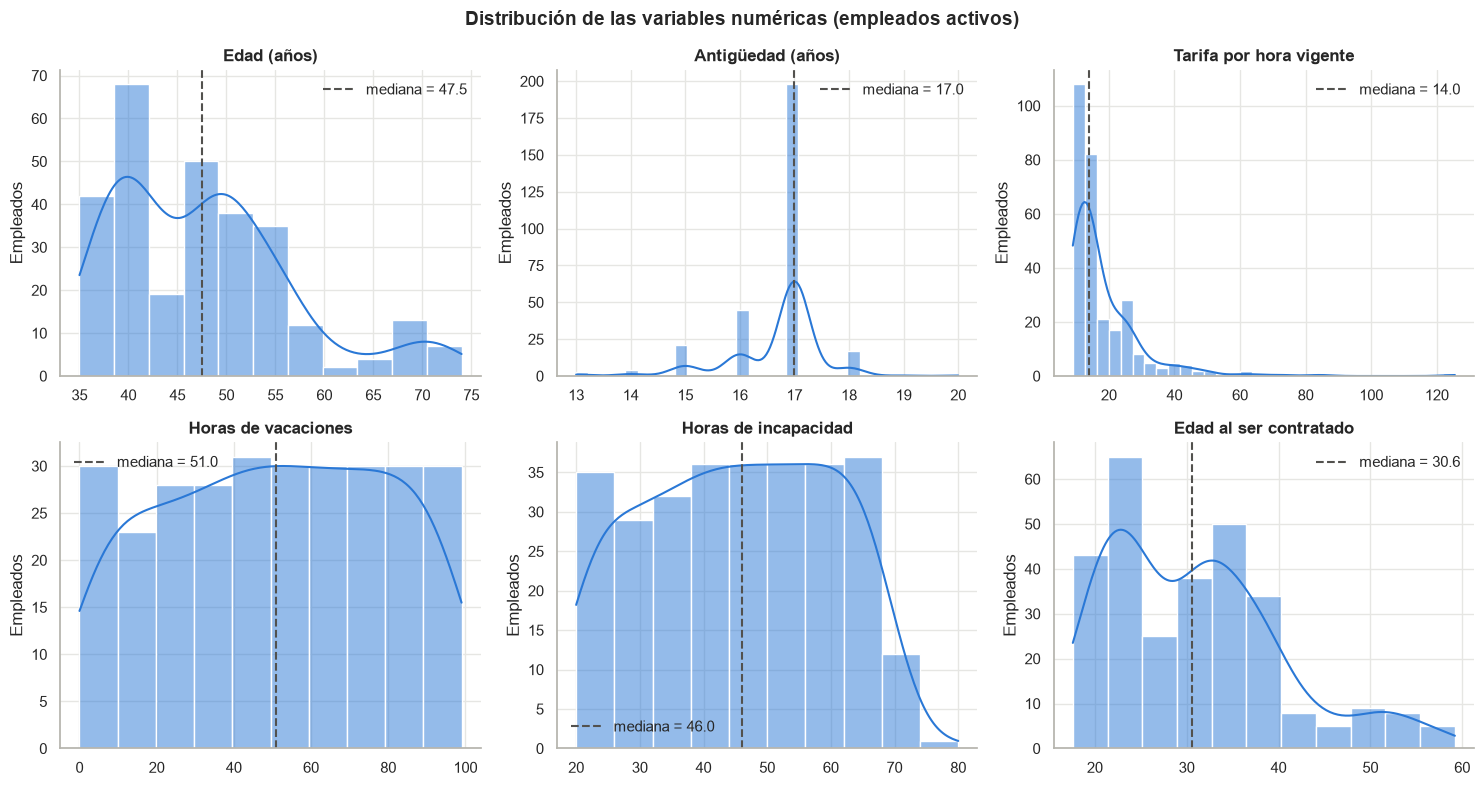

In [15]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
variables = [("edad", "Edad (años)"), ("antiguedad", "Antigüedad (años)"),
             ("tarifa_actual", "Tarifa por hora vigente"), ("vacationhours", "Horas de vacaciones"),
             ("sickleavehours", "Horas de incapacidad"), ("edad_contratacion", "Edad al ser contratado")]
for ax, (col, titulo) in zip(ejes.flat, variables):
    sns.histplot(activos[col], kde=True, ax=ax, color=PALETA[0], edgecolor="white", linewidth=1)
    ax.axvline(activos[col].median(), color="#52514e", ls="--", lw=1.5, label=f"mediana = {activos[col].median():,.1f}")
    ax.set_title(titulo); ax.set_xlabel(""); ax.set_ylabel("Empleados"); ax.legend(frameon=False)
fig.suptitle("Distribución de las variables numéricas (empleados activos)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

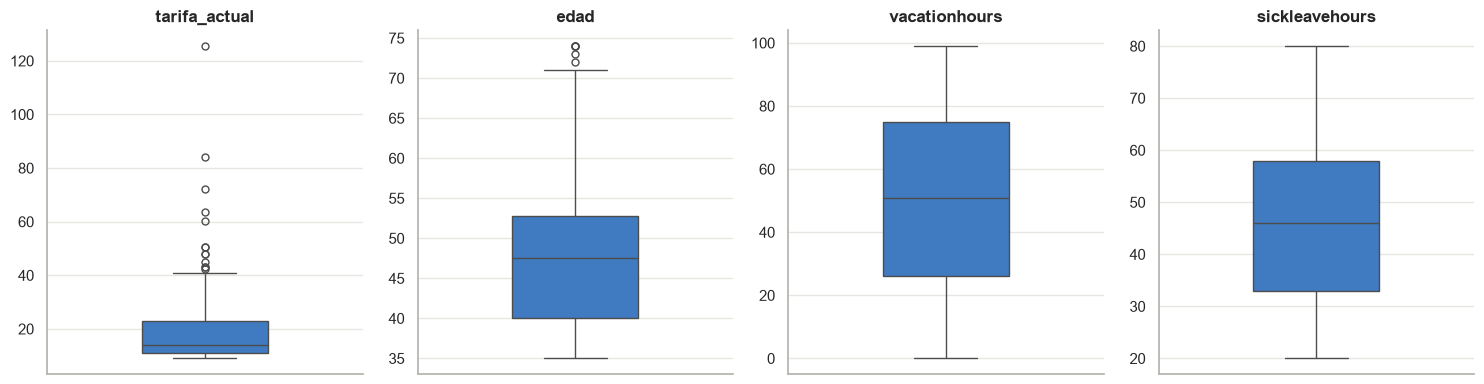

,edad,antiguedad,edad_contratacion,tarifa_actual,crecimiento_pct,n_cambios_salariales,n_traslados,vacationhours,sickleavehours,organizationlevel
atípicos (IQR),6,30,4,13,14,14,6,0,0,7


In [16]:
# Boxplots para detectar valores atípicos (regla de Tukey: fuera de Q1 − 1.5·IQR, Q3 + 1.5·IQR)
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for ax, col in zip(ejes, ["tarifa_actual", "edad", "vacationhours", "sickleavehours"]):
    sns.boxplot(y=activos[col], ax=ax, color=PALETA[0], width=0.4, fliersize=5)
    ax.set_title(col); ax.set_ylabel("")
plt.tight_layout(); plt.show()

def atipicos_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.Series({c: atipicos_iqr(activos[c]) for c in NUMERICAS}, name="atípicos (IQR)").to_frame().T

In [17]:
# ¿Quiénes son los atípicos de salario?
q1, q3 = activos["tarifa_actual"].quantile([0.25, 0.75])
limite = q3 + 1.5 * (q3 - q1)
print(f"Límite superior de Tukey para la tarifa: {limite:,.2f}")
activos.loc[activos["tarifa_actual"] > limite,
            ["firstname", "lastname", "jobtitle", "departamento", "organizationlevel", "tarifa_actual"]
           ].sort_values("tarifa_actual", ascending=False)

Límite superior de Tukey para la tarifa: 41.19


,firstname,lastname,jobtitle,departamento,organizationlevel,tarifa_actual
businessentityid,,,,,,
1,Ken,Sánchez,Chief Executive Officer,Executive,0.00,125.50
25,James,Hamilton,Vice President of Production,Production,1.00,84.13
273,Brian,Welcker,Vice President of Sales,Sales,1.00,72.12
2,Terri,Duffy,Vice President of Engineering,Engineering,1.00,63.46
234,Laura,Norman,Chief Financial Officer,Executive,1.00,60.10
7,Dylan,Miller,Research and Development Manager,Research and Development,3.00,50.48
263,Jean,Trenary,Information Services Manager,Information Services,1.00,50.48
287,Amy,Alberts,European Sales Manager,Sales,2.00,48.10
274,Stephen,Jiang,North American Sales Manager,Sales,2.00,48.10


**Interpretación** (290 empleados activos de AdventureWorks).

- **Tarifa por hora:** es la variable más asimétrica (asimetría ≈ 3.9). La mediana es 14 y el 75 % gana 23 o menos, pero hay una cola larga hasta 125.50 (el CEO). Los **13 atípicos** que marca el criterio IQR (por encima de ≈ 41) son todos directivos y gerentes: CEO, vicepresidentes, CFO y gerentes de ventas, ingeniería, finanzas e I+D. **No son errores**, así que no se eliminan; para el clustering se usa el **logaritmo** de la tarifa.
- **Antigüedad:** casi no varía. El **97 %** del personal tiene entre 15 y 19 años en la empresa, porque AdventureWorks contrató casi a todos entre 2008 y 2010. Es el dato real (el reporte de antigüedad de la app muestra lo mismo).
- **Edad:** va de 35 a 74 años, con mediana de 47.5 y leve asimetría a la derecha. Como la antigüedad es casi constante, la edad al contratar repite la misma información (ρ ≈ 0.99).
- **Vacaciones e incapacidad:** las vacaciones se reparten casi uniformemente entre 0 y 99 horas (curtosis negativa). Las horas de incapacidad tienen la misma forma; en el análisis bivariado se ve que son prácticamente la misma variable.
- **Historiales:** `n_cambios_salariales`, `n_traslados` y `crecimiento_pct` son 0 para casi todos, con coeficientes de variación por encima del 400 %.

### 6.2 Variables categóricas

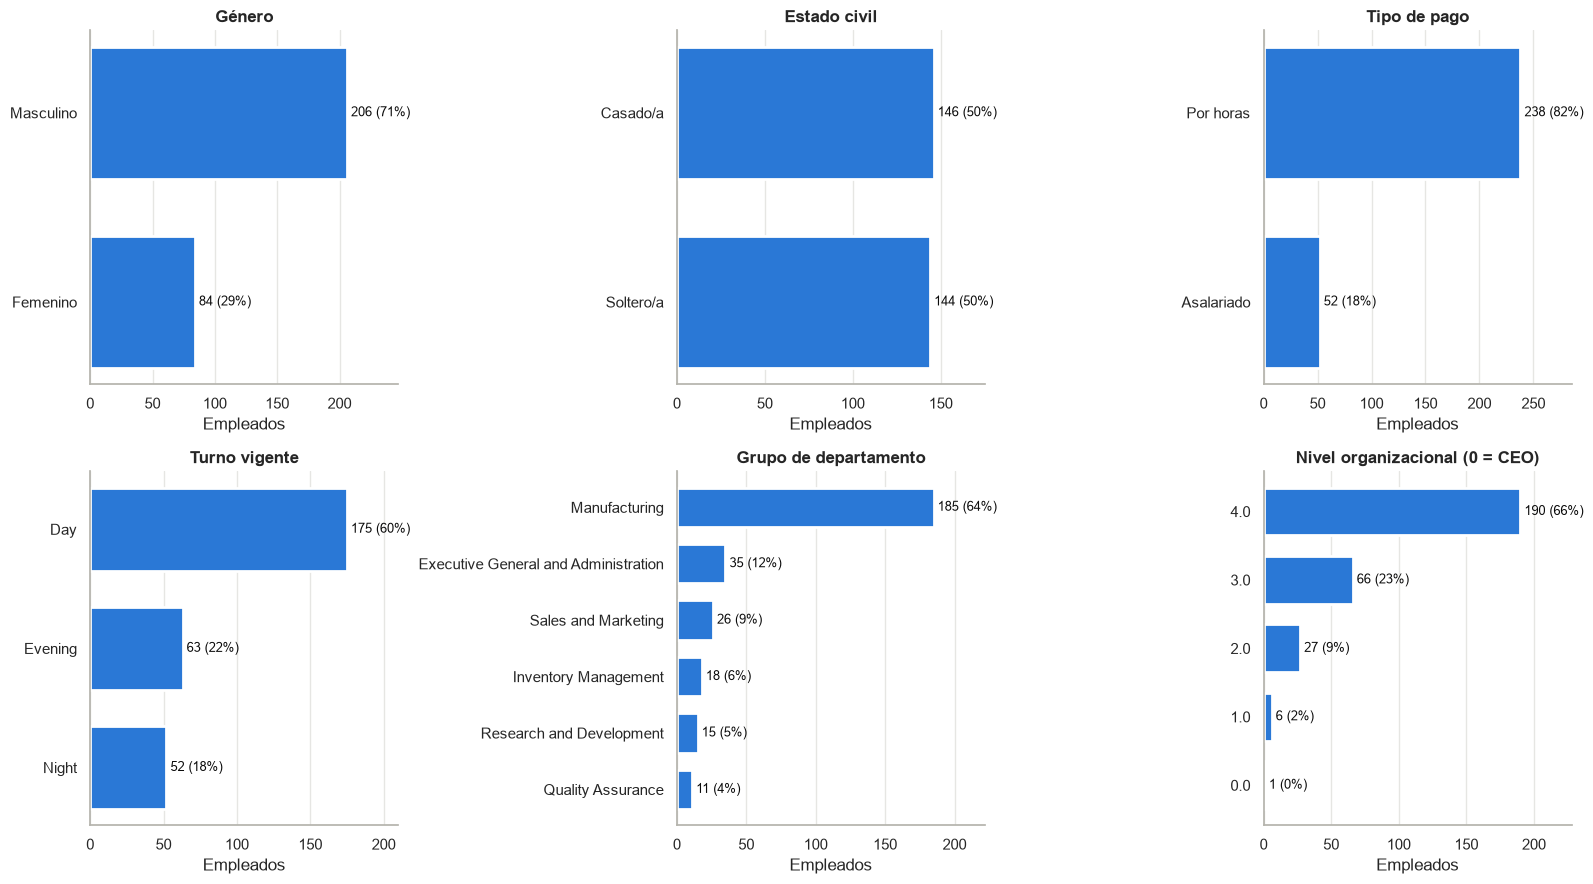

In [18]:
def barras_frecuencia(ax, serie, titulo, top=None):
    conteo = serie.value_counts()
    if top:
        conteo = conteo.head(top)
    conteo = conteo.sort_values()
    ax.barh(conteo.index.astype(str), conteo.values, color=PALETA[0], height=0.7, edgecolor="white", linewidth=2)
    total = len(serie)
    for i, v in enumerate(conteo.values):
        ax.text(v, i, f" {v} ({v / total:.0%})", va="center", fontsize=9, color="#0b0b0b")
    ax.set_title(titulo); ax.set_xlabel("Empleados"); ax.margins(x=0.2)
    ax.grid(axis="y", visible=False)

fig, ejes = plt.subplots(2, 3, figsize=(16, 9))
barras_frecuencia(ejes[0, 0], activos["genero"], "Género")
barras_frecuencia(ejes[0, 1], activos["estado_civil"], "Estado civil")
barras_frecuencia(ejes[0, 2], activos["tipo_pago"], "Tipo de pago")
barras_frecuencia(ejes[1, 0], activos["turno"], "Turno vigente")
barras_frecuencia(ejes[1, 1], activos["grupo"], "Grupo de departamento")
barras_frecuencia(ejes[1, 2], activos["organizationlevel"].astype(str), "Nivel organizacional (0 = CEO)")
plt.tight_layout(); plt.show()

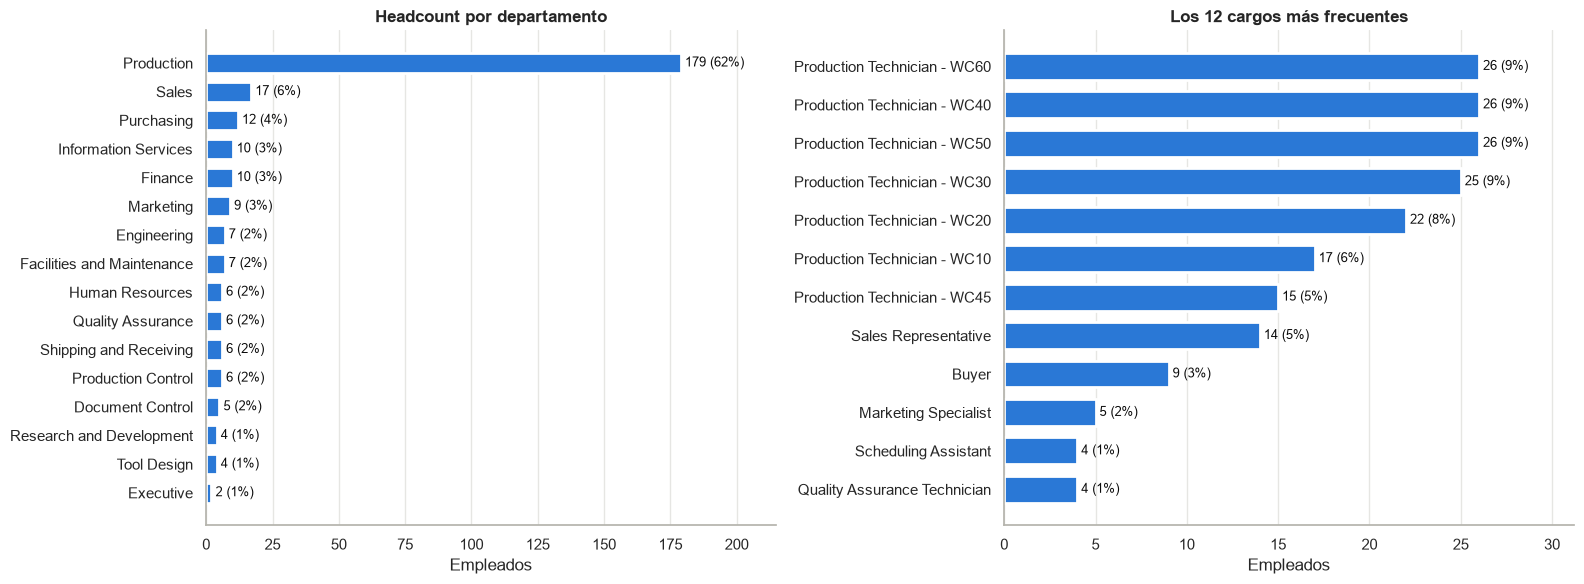

In [19]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6))
barras_frecuencia(ejes[0], activos["departamento"], "Headcount por departamento")
barras_frecuencia(ejes[1], activos["jobtitle"], "Los 12 cargos más frecuentes", top=12)
plt.tight_layout(); plt.show()

In [20]:
# Tramos de antigüedad (mismos cortes que el reporte de la app)
activos["tramo_antiguedad"].value_counts().sort_index().to_frame("empleados").assign(
    porcentaje=lambda d: (d["empleados"] / d["empleados"].sum() * 100).round(1))

,empleados,porcentaje
tramo_antiguedad,,
< 5,0,0.00
5–9,0,0.00
10–14,7,2.40
15–19,282,97.20
20+,1,0.30


**Interpretación.**

- **Concentración en Producción:** el departamento *Production* tiene **179 de 290 empleados (62 %)** y el grupo *Manufacturing*, 185 (64 %). Hay 67 cargos distintos, y los más frecuentes son técnicos de producción (*Production Technician* WC20 a WC60). Los otros 15 departamentos son pequeños: de 2 (*Executive*) a 17 (*Sales*) personas.
- **Género:** hay **mayoría masculina** (206 hombres, 71 %, contra 84 mujeres). El estado civil está balanceado (146 casados y 144 solteros).
- **Tipo de pago:** el **82 % trabaja por horas**. Solo 52 empleados son asalariados, y corresponden a cargos administrativos, profesionales y directivos.
- **Turnos:** 175 empleados en el de día (60 %), 63 en el de tarde y 52 en el de noche. Entre el 86 % y el 88 % de los turnos de tarde y noche son de Producción.
- **Jerarquía:** es una pirámide muy ancha en la base. Hay 1 CEO (nivel 0), 6 personas en el nivel 1, 27 en el 2, 66 en el 3 y **190 en el nivel 4 (66 %)**.

## 7. Análisis bivariado y multivariado

### 7.1 Correlaciones entre variables numéricas
Se usa **Spearman** (basada en rangos) porque varias variables son asimétricas o discretas.

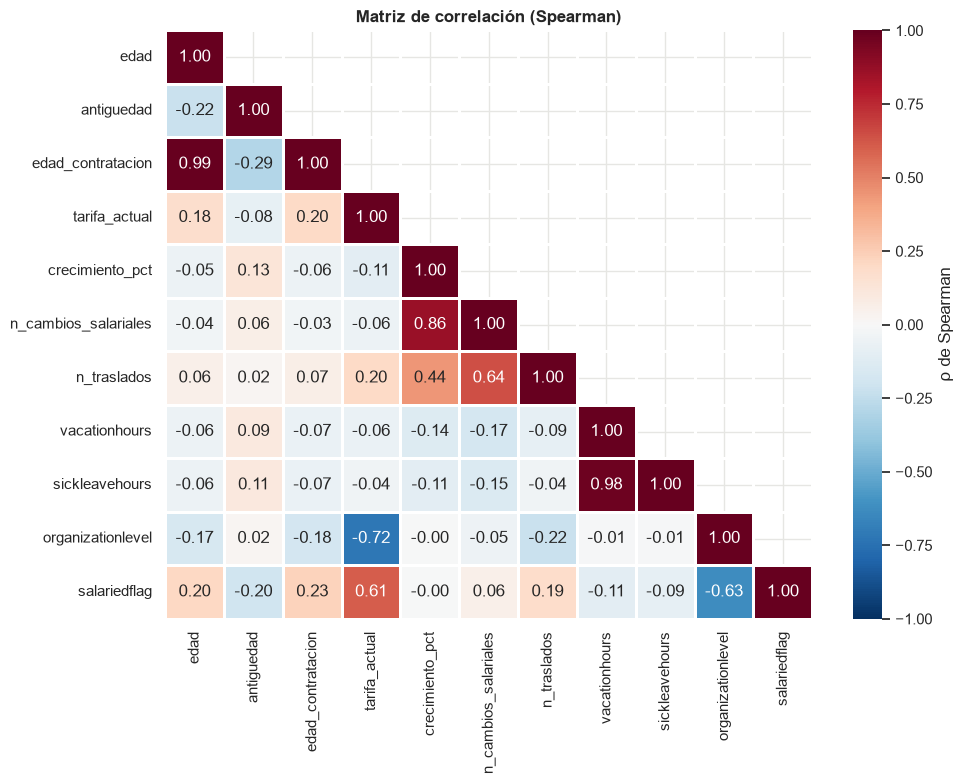

,level_0,level_1,rho
2,edad,edad_contratacion,0.99
85,vacationhours,sickleavehours,0.98
49,crecimiento_pct,n_cambios_salariales,0.86
42,tarifa_actual,organizationlevel,-0.72
61,n_cambios_salariales,n_traslados,0.64
109,organizationlevel,salariedflag,-0.63
43,tarifa_actual,salariedflag,0.61
50,crecimiento_pct,n_traslados,0.44


In [21]:
corr = activos[NUMERICAS + ["salariedflag"]].astype(float).corr(method="spearman")
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mascara, annot=True, fmt=".2f", cmap=DIVERGENTE, center=0, vmin=-1, vmax=1,
            linewidths=2, linecolor="white", cbar_kws={"label": "ρ de Spearman"})
plt.title("Matriz de correlación (Spearman)")
plt.tight_layout(); plt.show()

pares = (corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1)).stack()
         .rename("rho").reset_index().assign(abs_rho=lambda d: d["rho"].abs())
         .sort_values("abs_rho", ascending=False).head(8).drop(columns="abs_rho"))
pares

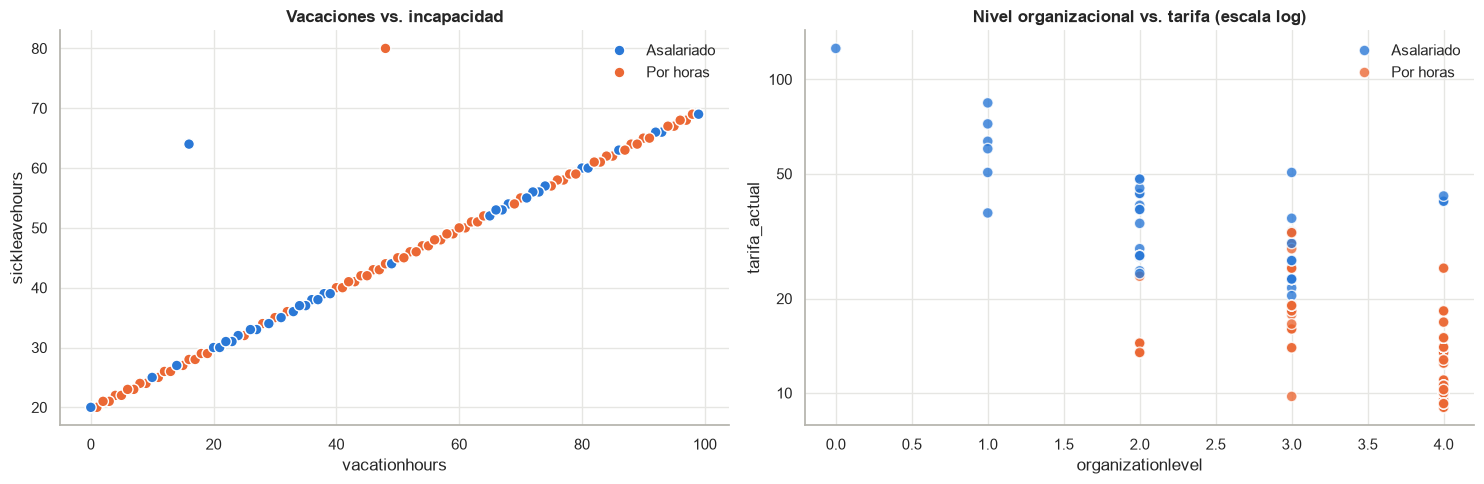

Pearson vacaciones–incapacidad: r = 0.978 (p = 5.3e-199)


In [22]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=activos, x="vacationhours", y="sickleavehours", hue="tipo_pago",
                palette=PALETA[:2], s=60, edgecolor="white", linewidth=1, ax=ejes[0])
ejes[0].set_title("Vacaciones vs. incapacidad"); ejes[0].legend(title="", frameon=False)
sns.scatterplot(data=activos, x="organizationlevel", y="tarifa_actual", hue="tipo_pago",
                palette=PALETA[:2], s=60, edgecolor="white", linewidth=1, ax=ejes[1], alpha=0.8)
eje_log(ejes[1])
ejes[1].set_title("Nivel organizacional vs. tarifa (escala log)"); ejes[1].legend(title="", frameon=False)
plt.tight_layout(); plt.show()

r, p = stats.pearsonr(activos["vacationhours"], activos["sickleavehours"])
print(f"Pearson vacaciones–incapacidad: r = {r:.3f} (p = {p:.1e})")

**Interpretación.**

- **Incapacidad y vacaciones:** las horas de incapacidad son prácticamente una función lineal de las de vacaciones (r de Pearson = 0.98). En AdventureWorks se generaron así, de modo que aportan la misma información. Por esta **redundancia**, en el clustering solo se conserva `vacationhours`.
- **Edad y edad al contratar:** también son redundantes (ρ = 0.99), porque todos llevan casi el mismo tiempo en la empresa.
- **Compensación:** la tarifa crece al **subir** en la jerarquía (ρ = −0.72 con `organizationlevel`). Además, los asalariados ganan más que el personal por horas: la mediana es 28.1 contra 13.5 (ρ = 0.61). Nivel, tipo de pago y tarifa forman un mismo eje de **posición en la organización**.

### 7.2 Salario por categorías

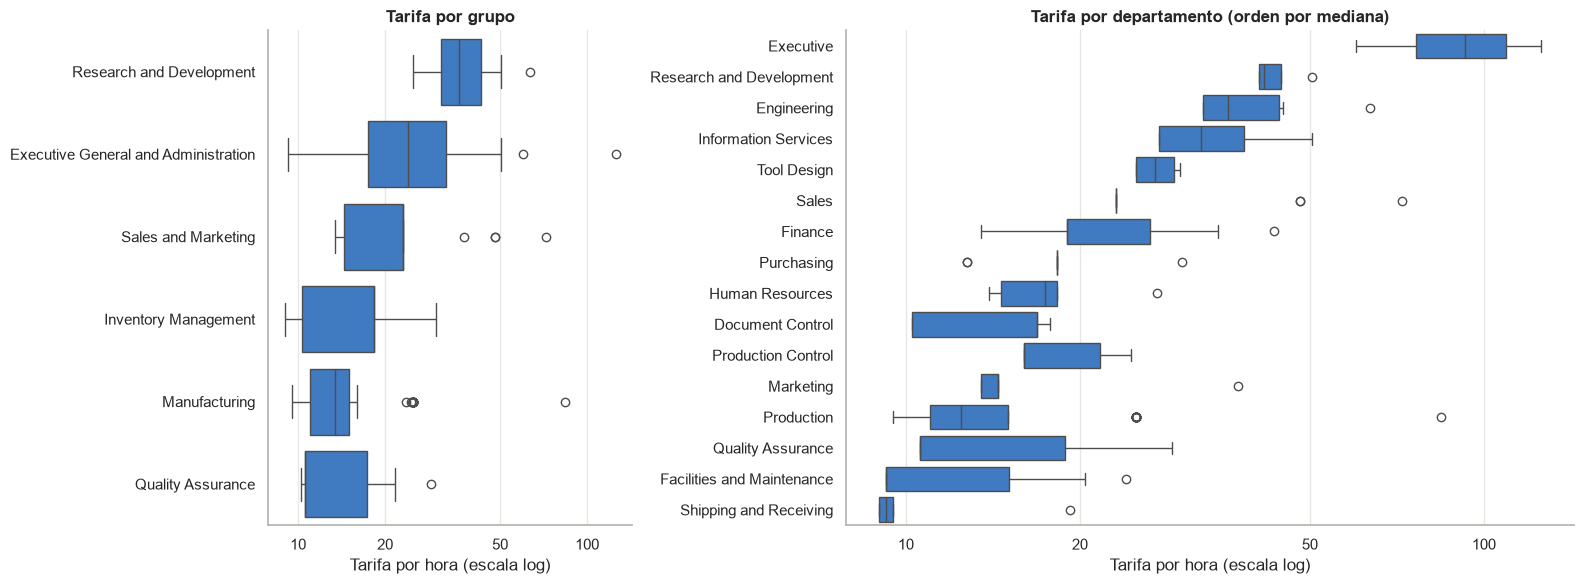

,empleados,media,mediana,minimo,maximo
departamento,,,,,
Executive,2,92.80,92.80,60.10,125.50
Research and Development,4,43.67,41.67,40.87,50.48
Engineering,7,40.84,36.06,32.69,63.46
Information Services,10,34.16,32.45,27.40,50.48
Sales,17,28.91,23.08,23.08,72.12
Tool Design,4,27.17,26.92,25.00,29.85
Finance,10,23.94,19.00,13.46,43.27
Production Control,6,18.68,16.00,16.00,24.52
Purchasing,12,18.33,18.27,12.75,30.00


In [23]:
orden_grupo = activos.groupby("grupo")["tarifa_actual"].median().sort_values(ascending=False).index
orden_dep = activos.groupby("departamento")["tarifa_actual"].median().sort_values(ascending=False).index

fig, ejes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1, 2]})
sns.boxplot(data=activos, x="tarifa_actual", y="grupo", order=orden_grupo, color=PALETA[0], ax=ejes[0])
eje_log(ejes[0], "x"); ejes[0].set_title("Tarifa por grupo"); ejes[0].set_ylabel("")
sns.boxplot(data=activos, x="tarifa_actual", y="departamento", order=orden_dep, color=PALETA[0], ax=ejes[1])
eje_log(ejes[1], "x"); ejes[1].set_title("Tarifa por departamento (orden por mediana)"); ejes[1].set_ylabel("")
for ax in ejes:
    ax.set_xlabel("Tarifa por hora (escala log)")
plt.tight_layout(); plt.show()

(activos.groupby("departamento")["tarifa_actual"]
 .agg(empleados="size", media="mean", mediana="median", minimo="min", maximo="max")
 .sort_values("media", ascending=False))

Kruskal-Wallis tarifa ~ grupo: H = 84.77, p = 8.42e-17


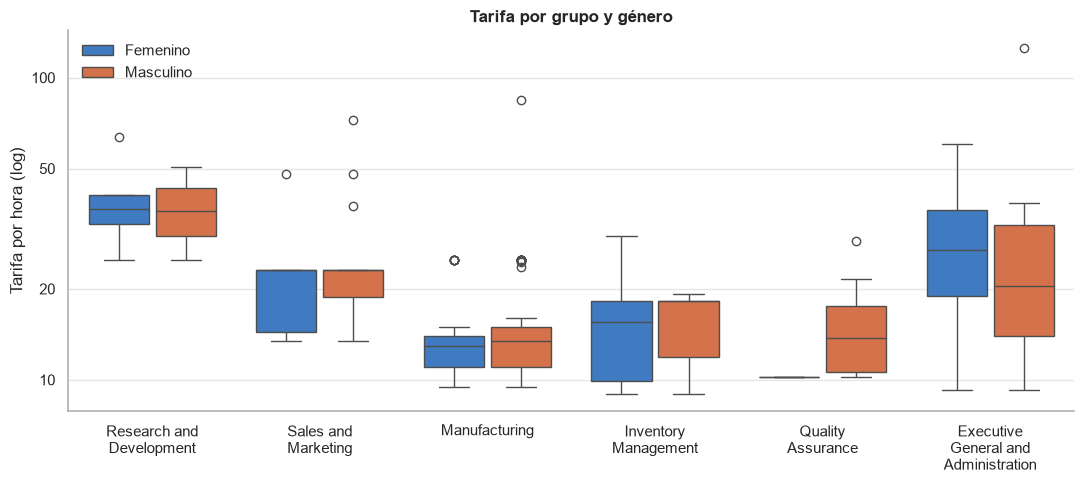

Mann-Whitney tarifa M vs F (global): U = 8,097, p = 0.391


genero,Femenino,Masculino
grupo,,
Executive General and Administration,26.79,20.43
Inventory Management,15.51,18.27
Manufacturing,12.95,13.45
Quality Assurance,10.25,13.70
Research and Development,36.78,36.06
Sales and Marketing,23.08,23.08


In [24]:
# Prueba de Kruskal-Wallis: ¿la tarifa difiere entre grupos de departamento?
muestras = [g["tarifa_actual"].values for _, g in activos.groupby("grupo")]
h, p = stats.kruskal(*muestras)
print(f"Kruskal-Wallis tarifa ~ grupo: H = {h:.2f}, p = {p:.2e}")

# Brecha por género: global y controlando por grupo
fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=activos, x="grupo", y="tarifa_actual", hue="genero", palette=PALETA[:2], ax=ax, gap=0.1)
eje_log(ax); envolver(ax)
ax.set_title("Tarifa por grupo y género"); ax.set_xlabel(""); ax.set_ylabel("Tarifa por hora (log)")
ax.legend(title="", frameon=False)
plt.tight_layout(); plt.show()

u, p = stats.mannwhitneyu(activos.loc[activos["gender"] == "M", "tarifa_actual"],
                          activos.loc[activos["gender"] == "F", "tarifa_actual"])
print(f"Mann-Whitney tarifa M vs F (global): U = {u:,.0f}, p = {p:.3f}")
activos.pivot_table(index="grupo", columns="genero", values="tarifa_actual", aggfunc="median")

**Interpretación.**

- **Área:** la tarifa depende del área. La prueba de Kruskal-Wallis da H = 84.8 con p < 0.001. *Executive* (media 92.8), I+D (43.7) e Ingeniería (40.8) son las áreas mejor pagadas. Las peor pagadas son *Shipping and Receiving* (10.9), *Facilities* (13.0) y *Production* (14.2), que concentra la mayor parte de la plantilla.
- **Género:** no hay diferencia significativa de tarifa entre hombres y mujeres (Mann-Whitney, p = 0.39). Dentro de cada grupo de departamento, las medianas son iguales o muy cercanas, y en algunos grupos son incluso mayores para las mujeres. Con estos datos **no se observa brecha salarial por género**.

### 7.3 Composición de la plantilla

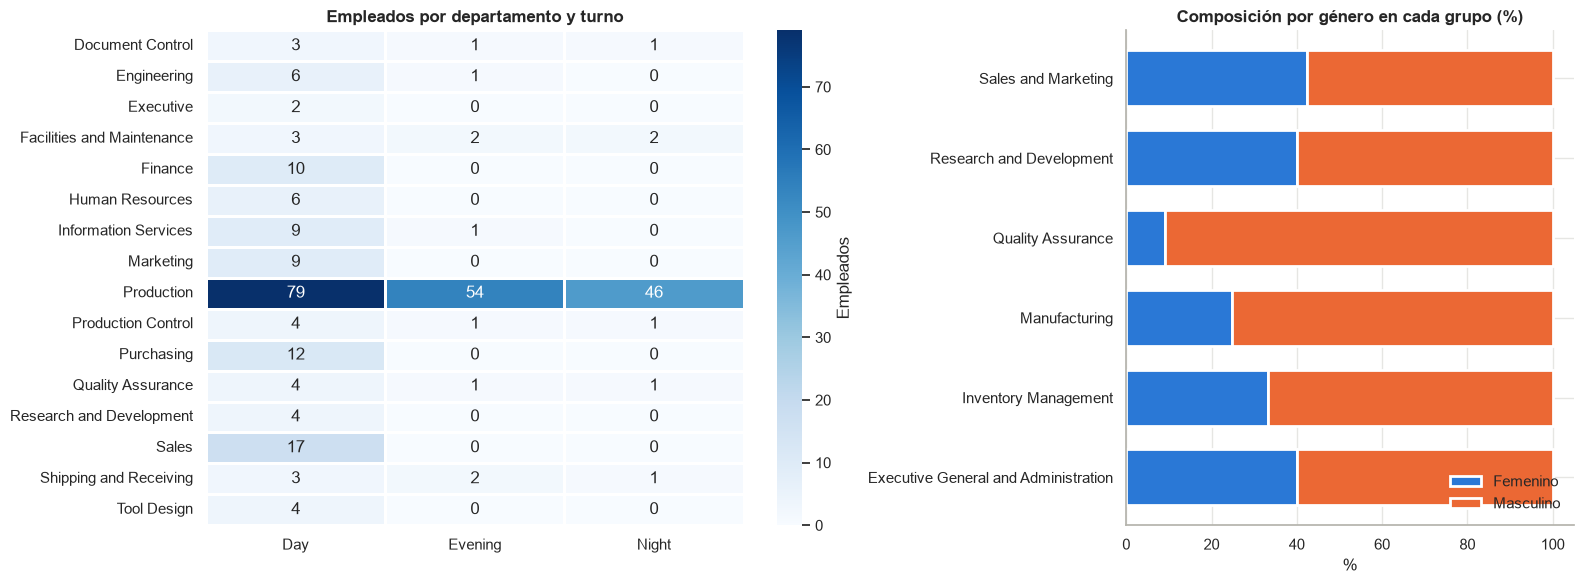

Chi² género ~ grupo: χ² = 9.00, gl = 5, p = 0.109


In [25]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 2]})
tabla_dt = pd.crosstab(activos["departamento"], activos["turno"])
sns.heatmap(tabla_dt, annot=True, fmt="d", cmap=SECUENCIAL, linewidths=2, linecolor="white",
            cbar_kws={"label": "Empleados"}, ax=ejes[0])
ejes[0].set_title("Empleados por departamento y turno"); ejes[0].set_ylabel(""); ejes[0].set_xlabel("")

genero_grupo = pd.crosstab(activos["grupo"], activos["genero"], normalize="index") * 100
genero_grupo.plot(kind="barh", stacked=True, color=PALETA[:2], ax=ejes[1], edgecolor="white", linewidth=2, width=0.7)
ejes[1].set_title("Composición por género en cada grupo (%)"); ejes[1].set_xlabel("%"); ejes[1].set_ylabel("")
ejes[1].legend(title="", frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

chi2, p, gl, _ = stats.chi2_contingency(pd.crosstab(activos["grupo"], activos["gender"]))
print(f"Chi² género ~ grupo: χ² = {chi2:.2f}, gl = {gl}, p = {p:.3f}")

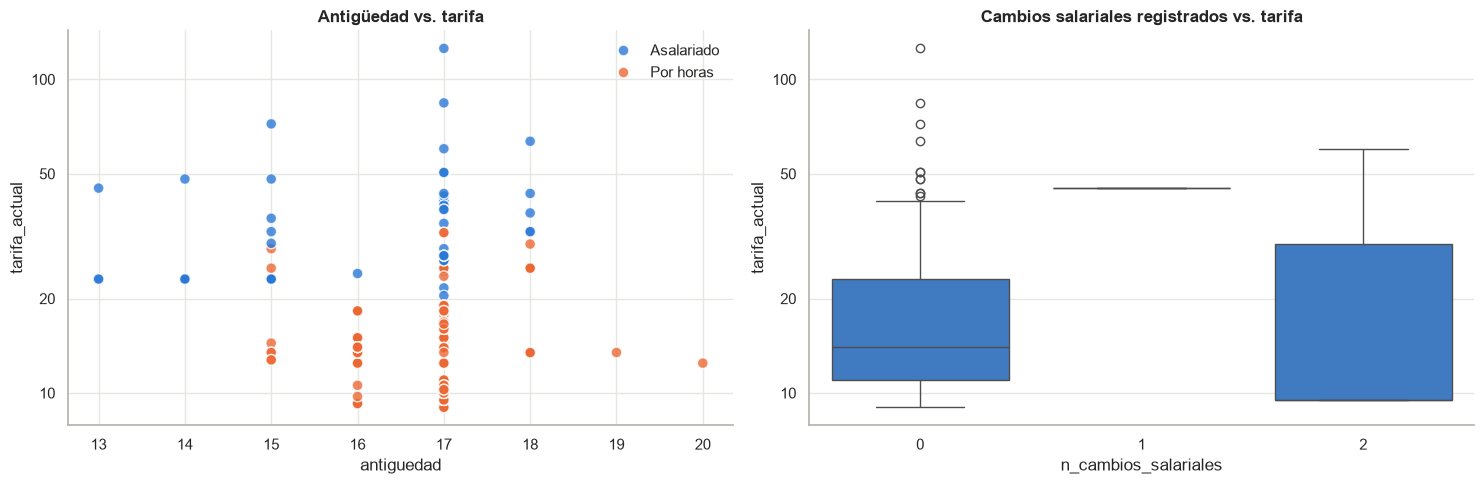

In [26]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=activos, x="antiguedad", y="tarifa_actual", hue="tipo_pago", palette=PALETA[:2],
                s=60, edgecolor="white", linewidth=1, alpha=0.8, ax=ejes[0])
eje_log(ejes[0])
ejes[0].set_title("Antigüedad vs. tarifa"); ejes[0].legend(title="", frameon=False)
sns.boxplot(data=activos, x="n_cambios_salariales", y="tarifa_actual", color=PALETA[0], ax=ejes[1])
eje_log(ejes[1])
ejes[1].set_title("Cambios salariales registrados vs. tarifa")
plt.tight_layout(); plt.show()

**Interpretación.**

- **Turnos:** Producción es el único departamento con presencia fuerte en los tres turnos (79 de día, 54 de tarde y 46 de noche). En los turnos de tarde y noche aparecen además unas pocas personas de soporte: mantenimiento, control de calidad, documentación y despacho. Las áreas administrativas trabajan solo de día.
- **Género por área:** la proporción de mujeres no depende significativamente del grupo de departamento (χ² = 9.0, p = 0.11).
- **Antigüedad y tarifa:** la antigüedad casi no explica la tarifa (la nube es plana). Pesa más **qué cargo** se ocupa que **cuánto tiempo** lleva la persona en la empresa.

## 8. Análisis temporal

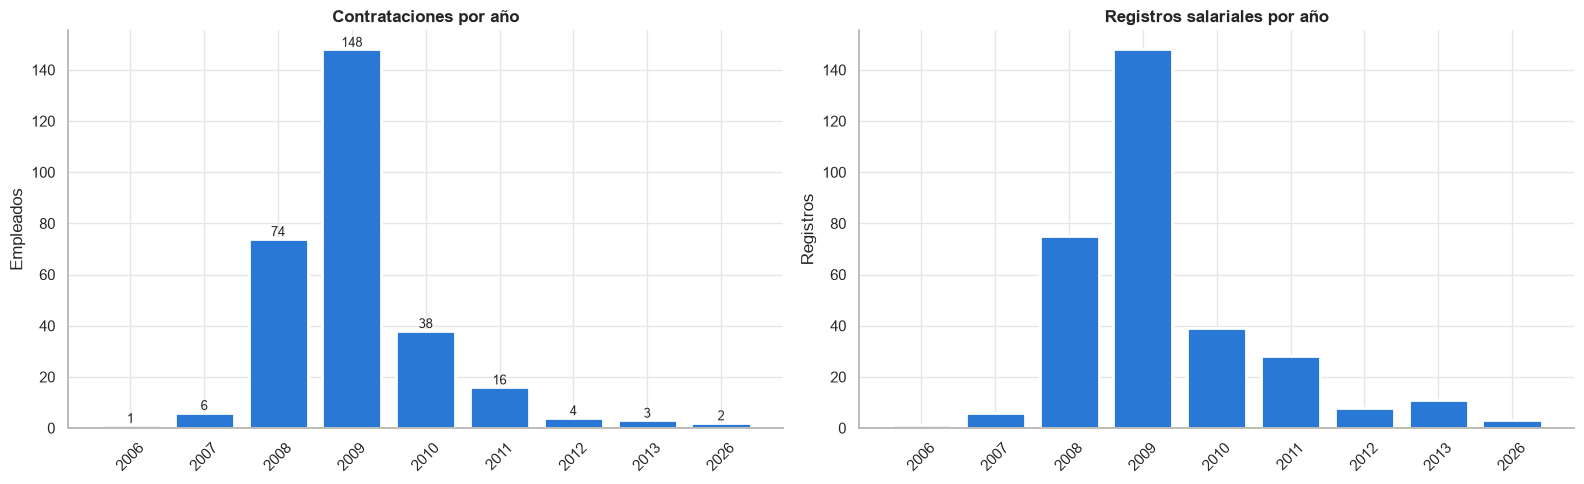

In [27]:
fig, ejes = plt.subplots(1, 2, figsize=(16, 5))
contr = emp.groupby("anio_contratacion").size()
ejes[0].bar(contr.index.astype(str), contr.values, color=PALETA[0], edgecolor="white", linewidth=2)
for x, v in zip(contr.index.astype(str), contr.values):
    ejes[0].text(x, v, str(v), ha="center", va="bottom", fontsize=9)
ejes[0].set_title("Contrataciones por año"); ejes[0].set_ylabel("Empleados"); ejes[0].tick_params(axis="x", rotation=45)

cambios = eph.assign(anio=eph["ratechangedate"].dt.year).groupby("anio").size()
ejes[1].bar(cambios.index.astype(str), cambios.values, color=PALETA[0], edgecolor="white", linewidth=2)
ejes[1].set_title("Registros salariales por año"); ejes[1].set_ylabel("Registros"); ejes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [28]:
# Trayectoria: crecimiento salarial de quienes tuvieron al menos un cambio
con_cambios = activos[activos["n_cambios_salariales"] > 0]
print(f"Empleados activos con algún cambio salarial: {len(con_cambios)} de {len(activos)} "
      f"({len(con_cambios) / len(activos):.0%})")
print(f"Empleados activos con algún traslado: {(activos['n_traslados'] > 0).sum()}")
con_cambios[["firstname", "lastname", "jobtitle", "tarifa_inicial", "tarifa_actual", "crecimiento_pct"]] \
    .sort_values("crecimiento_pct", ascending=False).head(10)

Empleados activos con algún cambio salarial: 14 de 290 (5%)
Empleados activos con algún traslado: 6


,firstname,lastname,jobtitle,tarifa_inicial,tarifa_actual,crecimiento_pct
businessentityid,,,,,,
4,Rob,Walters,Senior Tool Designer,8.62,29.85,246.24
250,Sheela,Word,Purchasing Manager,9.86,30.00,204.26
224,William,Vong,Scheduling Assistant,8.62,16.00,85.61
16,David,Bradley,Marketing Manager,24.00,37.50,56.25
234,Laura,Norman,Chief Financial Officer,39.06,60.10,53.86
167,David,Johnson,Production Technician - WC30,6.50,9.50,46.15
178,John,Frum,Production Technician - WC30,6.50,9.50,46.15
172,Marc,Ingle,Production Technician - WC30,6.50,9.50,46.15
170,George,Li,Production Technician - WC30,6.50,9.50,46.15


**Interpretación.**

- **Contrataciones:** se concentran en **2008 (74) y 2009 (148)**. Esos dos años reúnen el 77 % de la plantilla y corresponden a la puesta en marcha de Producción. Después de 2010 casi no se contrata.
- **Historiales cortos:** solo **14 de 290 empleados (5 %)** tuvieron algún cambio salarial y 6 algún traslado. Por eso `n_cambios_salariales`, `n_traslados` y `crecimiento_pct` sirven poco para separar grupos.
- **Casos llamativos de crecimiento:** los aumentos más grandes acompañan cambios de cargo. Por ejemplo, Rob Walters pasó de 8.62 a 29.85 (+246 %) y Sheela Word de 9.86 a 30.00 (+204 %).
- **Registros de 2026:** son operaciones hechas desde el SGRH.

## 9. Candidatos (`jobcandidate`)

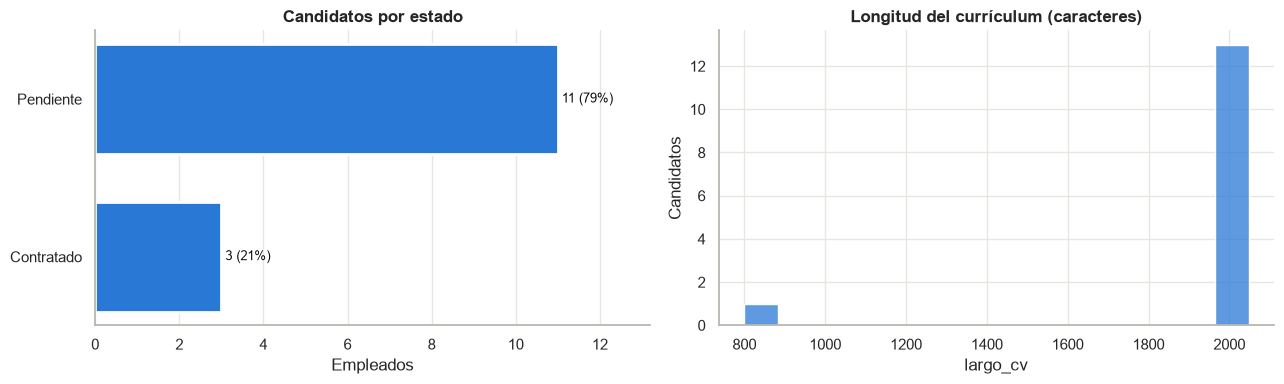

,candidatos,largo_cv_mediano,con_nombre_propio
estado,,,
Contratado,3,"2,048.00",3
Pendiente,11,"2,048.00",10


In [29]:
jc = jobcandidate.assign(
    estado=np.where(jobcandidate["businessentityid"].notna(), "Contratado", "Pendiente"),
    largo_cv=jobcandidate["resume"].fillna("").str.len(),
    tiene_nombre=jobcandidate["firstname"].notna(),
)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
barras_frecuencia(ejes[0], jc["estado"], "Candidatos por estado")
sns.histplot(jc["largo_cv"], bins=15, color=PALETA[0], edgecolor="white", ax=ejes[1])
ejes[1].set_title("Longitud del currículum (caracteres)"); ejes[1].set_ylabel("Candidatos")
plt.tight_layout(); plt.show()

jc.groupby("estado").agg(candidatos=("jobcandidateid", "size"),
                         largo_cv_mediano=("largo_cv", "median"),
                         con_nombre_propio=("tiene_nombre", "sum"))

**Interpretación.**

- **Tamaño:** la tabla de candidatos es **pequeña**: 14 filas, de las cuales 3 están contratadas. Solo admite análisis descriptivo; no tiene tamaño suficiente para clustering.
- **Currículums:** todos los originales miden exactamente 2048 caracteres, lo que indica que la migración los truncó (ver la sección 4). El único currículum de otra longitud es el de un candidato creado desde el SGRH.
- **Nombres:** las columnas `firstname`/`lastname` se agregaron en el proyecto y están completas, salvo en 1 registro de prueba.

## 10. Análisis de clusters

**Pregunta:** ¿existen **perfiles naturales de empleados** según su edad, trayectoria, compensación y posición en la organización?

### 10.1 Selección y preparación de variables

| Variable | Se usa | Motivo |
|---|---|---|
| `edad` | Sí | Perfil demográfico |
| `log_tarifa` | Sí | Compensación; el log corrige la fuerte asimetría |
| `organizationlevel` | Sí | Posición jerárquica |
| `vacationhours` | Sí | Beneficios acumulados |
| `salariedflag` | **No** (se usa para describir) | Al ser binaria domina la distancia: con ella K-Means elige k = 2 y solo separa asalariados de no asalariados (se comprueba abajo). Además está muy correlacionada con tarifa y nivel |
| `antiguedad` | **No** | Casi constante: ~97 % de la plantilla está en el tramo 15–19 años |
| `edad_contratacion` | **No** | Redundante con `edad` (ρ ≈ 0.99), justamente porque la antigüedad casi no varía |
| `sickleavehours` | **No** | Redundante con `vacationhours` (ρ ≈ 0.98) |
| `n_cambios_salariales`, `n_traslados`, `crecimiento_pct` | **No** | Casi constantes (mayoría de ceros) |
| departamento, turno, género, estado civil | **No** (se usan para *describir* los clusters) | K-Means usa distancia euclidiana, poco adecuada para categóricas; además así los clusters no quedan definidos por el organigrama |

Las variables se **estandarizan** (media 0, desviación 1) para que ninguna domine la distancia por su escala.

In [30]:
activos["log_tarifa"] = np.log(activos["tarifa_actual"])
VARS_CLUSTER = ["edad", "log_tarifa", "organizationlevel", "vacationhours"]

X_df = activos[VARS_CLUSTER].astype(float).dropna()
print(f"Filas para clustering: {len(X_df)} (descartadas por nulos: {len(activos) - len(X_df)})")
escalador = StandardScaler()
X = escalador.fit_transform(X_df)
pd.DataFrame(X, columns=VARS_CLUSTER).describe().loc[["mean", "std"]].round(2)

Filas para clustering: 290 (descartadas por nulos: 0)


,edad,log_tarifa,organizationlevel,vacationhours
mean,0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00


### 10.2 Número de clusters (k)

Se prueban k = 2 … 10 con cuatro criterios:

- **Codo (inercia)**: suma de distancias al centroide; se busca donde deja de bajar con fuerza.
- **Silueta**: cohesión vs. separación, de −1 a 1 (más alto es mejor).
- **Calinski-Harabasz**: separación entre clusters / dispersión interna (más alto es mejor).
- **Davies-Bouldin**: similitud promedio entre clusters (más bajo es mejor).

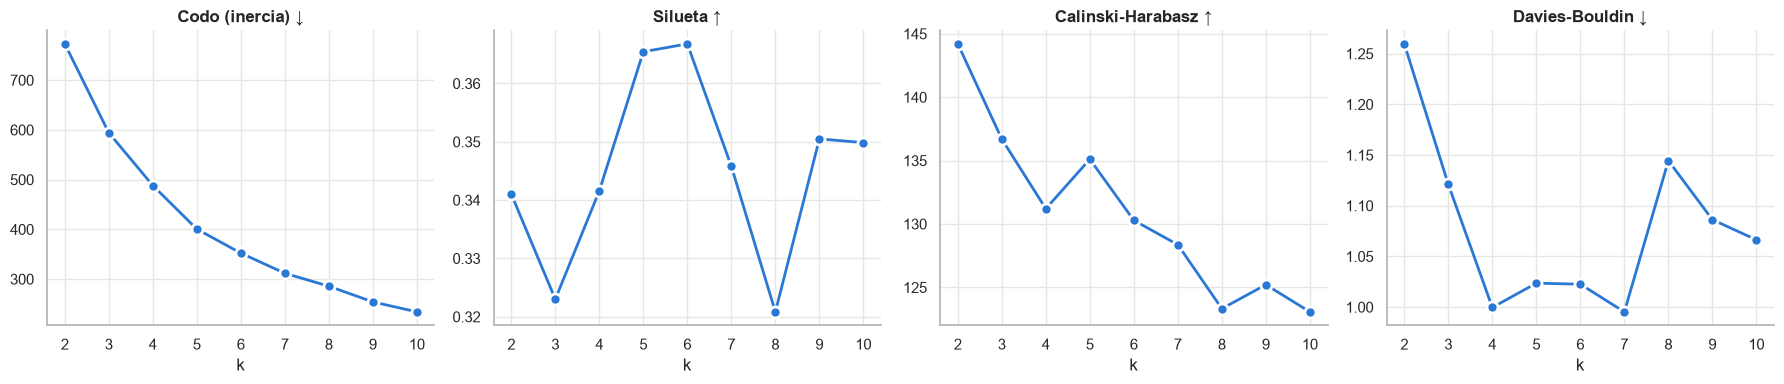

,inercia,silueta,calinski_harabasz,davies_bouldin
k,,,,
2,772.97,0.34,144.20,1.26
3,594.09,0.32,136.69,1.12
4,488.16,0.34,131.20,1.00
5,400.52,0.37,135.11,1.02
6,352.18,0.37,130.28,1.02
7,311.70,0.35,128.36,1.00
8,285.63,0.32,123.32,1.14
9,254.12,0.35,125.21,1.09
10,234.07,0.35,123.07,1.07


In [31]:
rango_k = range(2, 11)
filas = []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit(X)
    filas.append({"k": k, "inercia": km.inertia_,
                  "silueta": silhouette_score(X, km.labels_),
                  "calinski_harabasz": calinski_harabasz_score(X, km.labels_),
                  "davies_bouldin": davies_bouldin_score(X, km.labels_)})
metricas = pd.DataFrame(filas).set_index("k")

fig, ejes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (col, titulo) in zip(ejes, [("inercia", "Codo (inercia) ↓"), ("silueta", "Silueta ↑"),
                                    ("calinski_harabasz", "Calinski-Harabasz ↑"), ("davies_bouldin", "Davies-Bouldin ↓")]):
    ax.plot(metricas.index, metricas[col], marker="o", color=PALETA[0], lw=2, ms=8,
            markeredgecolor="white", markeredgewidth=2)
    ax.set_title(titulo); ax.set_xlabel("k"); ax.set_xticks(list(rango_k))
plt.tight_layout(); plt.show()
metricas

In [32]:
# Selección de k por parsimonia: el menor k cuya silueta esté a menos de 0.01 de la máxima
# (una diferencia menor no justifica agregar un grupo más, más difícil de interpretar).
mejor = metricas["silueta"].idxmax()
K = int(metricas.index[metricas["silueta"] >= metricas["silueta"].max() - 0.01].min())
print(f"k con mejor silueta: {mejor} | k elegido: {K} (silueta = {metricas.loc[K, 'silueta']:.3f})")

k con mejor silueta: 6 | k elegido: 5 (silueta = 0.365)


In [33]:
# Comprobación: ¿qué pasa si se agrega salariedflag (0/1)?
X_con_flag = StandardScaler().fit_transform(activos.loc[X_df.index, VARS_CLUSTER + ["salariedflag"]].astype(float))
siluetas_flag = {k: silhouette_score(X_con_flag, KMeans(n_clusters=k, n_init=20, random_state=SEMILLA).fit_predict(X_con_flag))
                 for k in rango_k}
pd.DataFrame({"silueta sin salariedflag": metricas["silueta"], "silueta con salariedflag": pd.Series(siluetas_flag)}).round(3).T

,2,3,4,5,6,7,8,9,10
silueta sin salariedflag,0.34,0.32,0.34,0.36,0.37,0.35,0.32,0.35,0.35
silueta con salariedflag,0.47,0.31,0.34,0.39,0.39,0.36,0.36,0.37,0.36


Con `salariedflag` la silueta de k = 2 sube de forma artificial: el algoritmo solo corta por la variable binaria, que ya se conoce de antemano. Sin ella aparecen grupos que combinan edad, compensación, jerarquía y vacaciones, que es lo que interesa descubrir.

### 10.3 K-Means con el k elegido

In [34]:
kmeans = KMeans(n_clusters=K, n_init=50, random_state=SEMILLA).fit(X)

# Se numeran los clusters por tarifa media ascendente para que la lectura sea estable entre corridas
orden = pd.Series(kmeans.labels_).groupby(kmeans.labels_).apply(lambda idx: X_df["log_tarifa"].iloc[idx.index].mean())
renumerar = {viejo: nuevo for nuevo, viejo in enumerate(orden.sort_values().index)}
activos.loc[X_df.index, "cluster"] = pd.Series(kmeans.labels_, index=X_df.index).map(renumerar)
activos["cluster"] = activos["cluster"].astype("Int64")

# Estabilidad: ¿se obtiene la misma partición con otras semillas?
ari_semillas = [adjusted_rand_score(kmeans.labels_, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X))
                for s in range(10)]
print(f"Estabilidad entre semillas (ARI medio): {np.mean(ari_semillas):.3f}  (1 = idéntica)")
activos["cluster"].value_counts().sort_index().to_frame("empleados")

Estabilidad entre semillas (ARI medio): 0.986  (1 = idéntica)


,empleados
cluster,
0,93
1,57
2,42
3,84
4,14


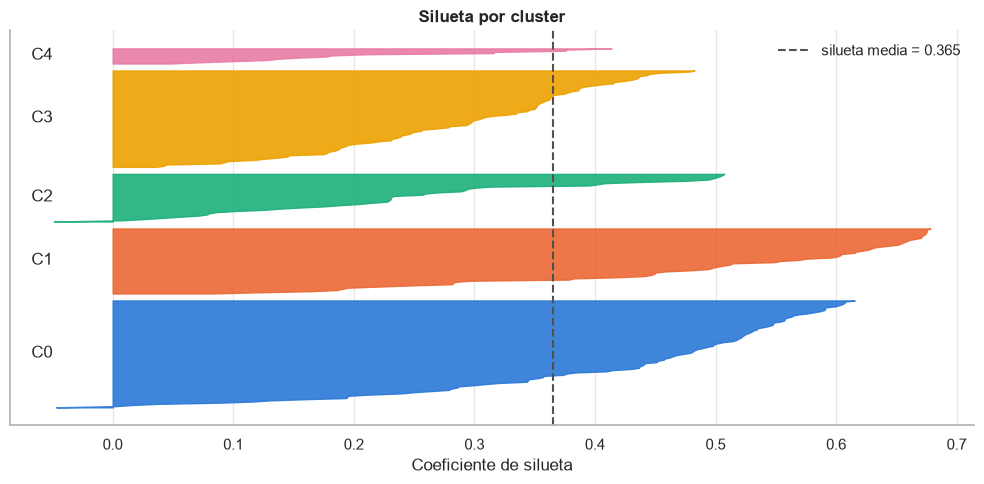

Puntos con silueta negativa: 2


In [35]:
# Silueta por observación: valores negativos = puntos posiblemente mal asignados
sil = silhouette_samples(X, activos.loc[X_df.index, "cluster"].astype(int))
fig, ax = plt.subplots(figsize=(10, 5))
y = 0
for c in range(K):
    valores = np.sort(sil[activos.loc[X_df.index, "cluster"].astype(int).values == c])
    ax.fill_betweenx(np.arange(y, y + len(valores)), 0, valores, color=PALETA[c], alpha=0.9)
    ax.text(-0.05, y + len(valores) / 2, f"C{c}", ha="right", va="center")
    y += len(valores) + 5
ax.axvline(sil.mean(), color="#52514e", ls="--", label=f"silueta media = {sil.mean():.3f}")
ax.set_xlabel("Coeficiente de silueta"); ax.set_yticks([]); ax.legend(frameon=False)
ax.set_title("Silueta por cluster")
plt.tight_layout(); plt.show()
print(f"Puntos con silueta negativa: {(sil < 0).sum()}")

### 10.4 Visualización con PCA

Los clusters viven en 4 dimensiones; para verlos se proyectan sobre las **dos primeras componentes principales**. Las flechas muestran cuánto aporta cada variable original a cada componente.

Varianza explicada: [0.458 0.251] (total 71.0%)


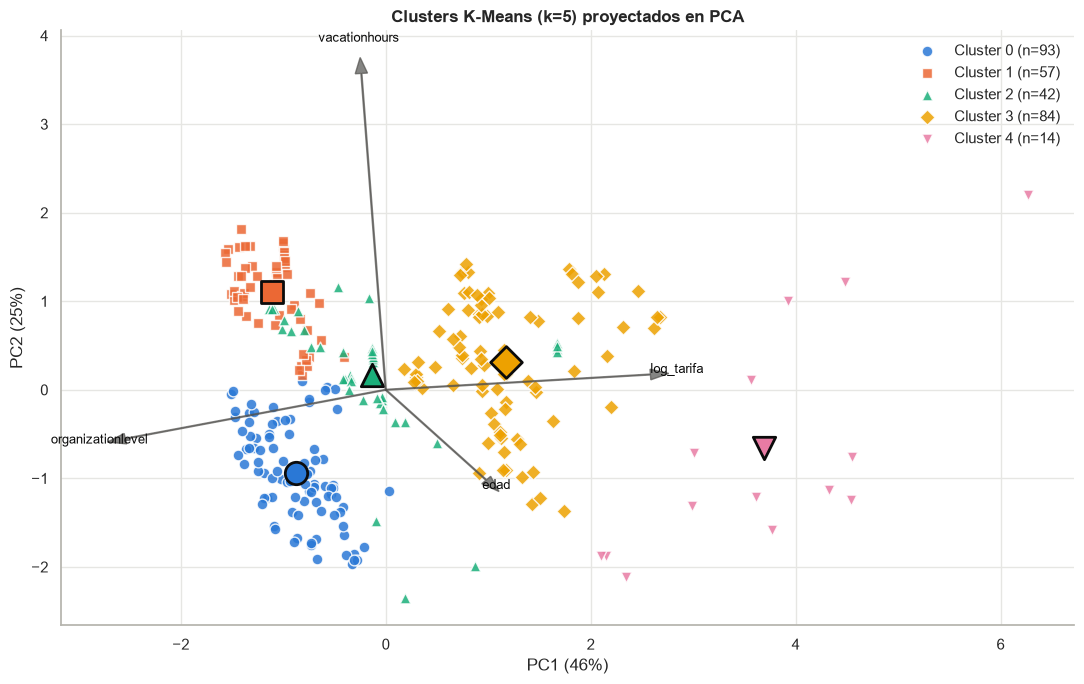

,PC1,PC2
edad,0.26,-0.27
log_tarifa,0.69,0.05
organizationlevel,-0.68,-0.15
vacationhours,-0.06,0.95


In [36]:
pca = PCA(n_components=2, random_state=SEMILLA).fit(X)
P = pca.transform(X)
etiquetas = activos.loc[X_df.index, "cluster"].astype(int).values
print("Varianza explicada:", np.round(pca.explained_variance_ratio_, 3),
      f"(total {pca.explained_variance_ratio_.sum():.1%})")

fig, ax = plt.subplots(figsize=(11, 7))
for c in range(K):
    m = etiquetas == c
    ax.scatter(P[m, 0], P[m, 1], s=60, color=PALETA[c], marker=MARCADORES[c],
               edgecolor="white", linewidth=1, alpha=0.85, label=f"Cluster {c} (n={m.sum()})")
centros = pca.transform(kmeans.cluster_centers_)
for viejo, nuevo in renumerar.items():
    ax.scatter(*centros[viejo], s=260, color=PALETA[nuevo], marker=MARCADORES[nuevo], edgecolor="#0b0b0b", linewidth=2)
escala = np.abs(P).max() * 0.6
for i, var in enumerate(VARS_CLUSTER):
    dx, dy = pca.components_[0, i] * escala, pca.components_[1, i] * escala
    ax.arrow(0, 0, dx, dy, color="#52514e", width=0.01, head_width=0.12, alpha=0.7)
    ax.text(dx * 1.1, dy * 1.1, var, color="#0b0b0b", fontsize=9, ha="center")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%})"); ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.set_title(f"Clusters K-Means (k={K}) proyectados en PCA")
ax.legend(frameon=False, loc="best")
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_.T, index=VARS_CLUSTER, columns=["PC1", "PC2"]).round(2)

### 10.5 Perfil de cada cluster

In [37]:
perfil = activos.groupby("cluster").agg(
    empleados=("edad", "size"),
    edad=("edad", "mean"),
    antiguedad=("antiguedad", "mean"),
    tarifa_media=("tarifa_actual", "mean"),
    tarifa_mediana=("tarifa_actual", "median"),
    nivel_org=("organizationlevel", "mean"),
    vacaciones=("vacationhours", "mean"),
    pct_asalariados=("salariedflag", lambda s: s.mean() * 100),
    pct_mujeres=("gender", lambda s: (s == "F").mean() * 100),
    pct_casados=("maritalstatus", lambda s: (s == "M").mean() * 100),
    pct_produccion=("departamento", lambda s: (s == "Production").mean() * 100),
)
perfil

,empleados,edad,antiguedad,tarifa_media,tarifa_mediana,nivel_org,vacaciones,pct_asalariados,pct_mujeres,pct_casados,pct_produccion
cluster,,,,,,,,,,,
0,93,45.17,16.85,12.07,12.45,4.00,23.54,0.00,23.66,53.76,96.77
1,57,40.86,16.82,12.20,11.00,4.00,81.65,0.00,29.82,43.86,77.19
2,42,61.26,16.71,15.12,15.00,3.88,70.12,0.00,28.57,57.14,64.29
3,84,46.95,16.46,24.32,23.80,2.76,54.04,45.24,32.14,46.43,20.24
4,14,57.57,16.43,55.42,48.10,1.64,25.07,100.00,42.86,57.14,7.14


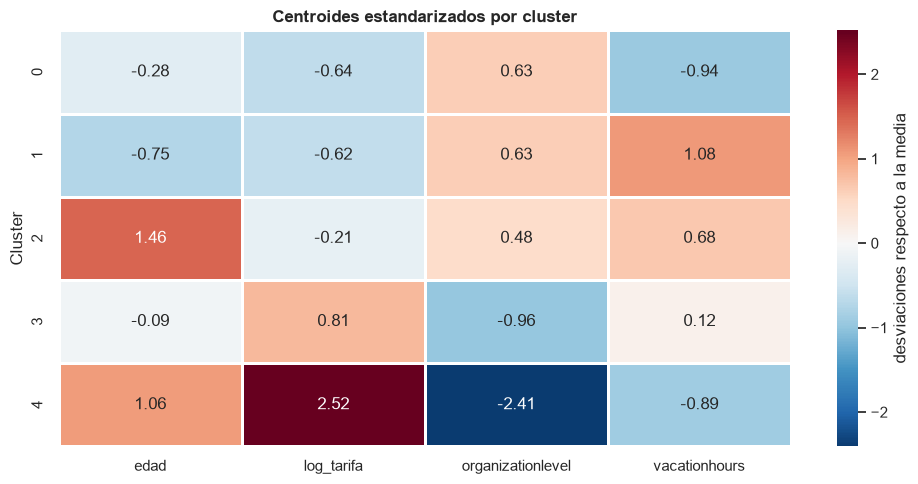

,rasgos dominantes
cluster,
0,"pocas horas de vacaciones, tarifa baja"
1,"muchas horas de vacaciones, más jóvenes"
2,"mayor edad, muchas horas de vacaciones"
3,"niveles altos de jerarquía, tarifa alta"
4,"tarifa alta, niveles altos de jerarquía"


In [38]:
# Mapa de calor de los centroides en unidades estandarizadas (z): qué distingue a cada cluster
z = pd.DataFrame(X, index=X_df.index, columns=VARS_CLUSTER).groupby(activos.loc[X_df.index, "cluster"]).mean()
plt.figure(figsize=(10, 0.6 * K + 2))
sns.heatmap(z, annot=True, fmt=".2f", cmap=DIVERGENTE, center=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "desviaciones respecto a la media"})
plt.title("Centroides estandarizados por cluster"); plt.ylabel("Cluster")
plt.tight_layout(); plt.show()

# Nombre descriptivo automático: los dos rasgos más marcados de cada cluster
NOMBRES_VAR = {"edad": ("mayor edad", "más jóvenes"),
               "log_tarifa": ("tarifa alta", "tarifa baja"), "organizationlevel": ("niveles bajos de jerarquía", "niveles altos de jerarquía"),
               "vacationhours": ("muchas horas de vacaciones", "pocas horas de vacaciones")}
def describir(fila):
    top = fila.abs().sort_values(ascending=False).head(2).index
    return ", ".join(NOMBRES_VAR[v][0] if fila[v] > 0 else NOMBRES_VAR[v][1] for v in top)
z.apply(describir, axis=1).rename("rasgos dominantes").to_frame()

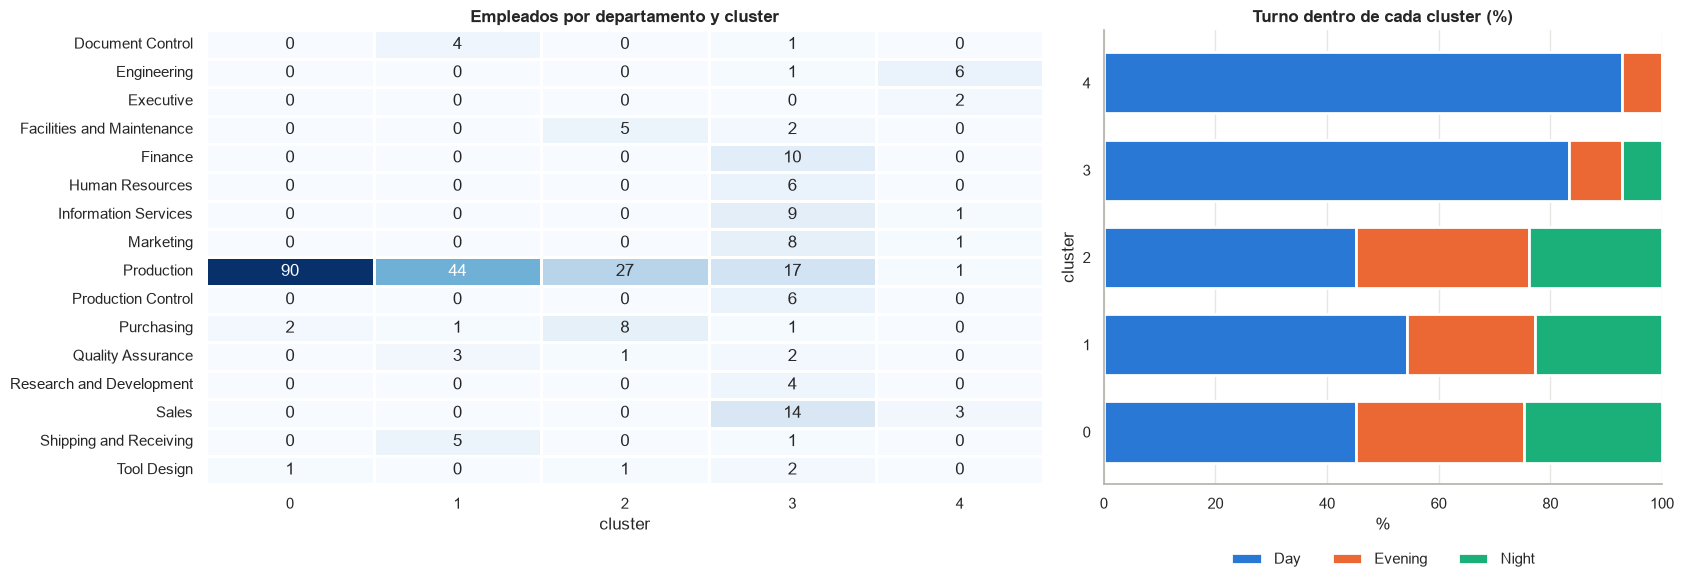

Cluster 0 — cargos más frecuentes: Production Technician - WC60 (25); Production Technician - WC30 (25); Production Technician - WC20 (21); Production Technician - WC50 (14); Production Technician - WC40 (5)
Cluster 1 — cargos más frecuentes: Production Technician - WC40 (12); Production Technician - WC50 (11); Production Technician - WC45 (11); Production Technician - WC10 (10); Stocker (3)
Cluster 2 — cargos más frecuentes: Production Technician - WC40 (9); Buyer (8); Production Technician - WC10 (7); Production Technician - WC45 (4); Janitor (4)
Cluster 3 — cargos más frecuentes: Sales Representative (14); Marketing Specialist (5); Scheduling Assistant (4); Application Specialist (4); Marketing Assistant (3)
Cluster 4 — cargos más frecuentes: Design Engineer (3); Vice President of Engineering (1); Engineering Manager (1); Marketing Manager (1); Vice President of Production (1)


In [39]:
# Composición de cada cluster por departamento y por grupo (variables NO usadas para formar los clusters)
fig, ejes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [3, 2]})
sns.heatmap(pd.crosstab(activos["departamento"], activos["cluster"]), annot=True, fmt="d", cmap=SECUENCIAL,
            linewidths=2, linecolor="white", ax=ejes[0], cbar=False)
ejes[0].set_title("Empleados por departamento y cluster"); ejes[0].set_ylabel("")
comp = pd.crosstab(activos["cluster"], activos["turno"], normalize="index") * 100
comp.plot(kind="barh", stacked=True, color=PALETA[:comp.shape[1]], ax=ejes[1], edgecolor="white", linewidth=2, width=0.7)
ejes[1].set_title("Turno dentro de cada cluster (%)"); ejes[1].set_xlabel("%"); ejes[1].legend(frameon=False, title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.tight_layout(); plt.show()

for c in range(K):
    cargos = activos.loc[activos["cluster"] == c, "jobtitle"].value_counts().head(5)
    print(f"Cluster {c} — cargos más frecuentes: " + "; ".join(f"{t} ({n})" for t, n in cargos.items()))

In [40]:
# ¿Las diferencias entre clusters son significativas? Kruskal-Wallis por variable
pd.DataFrame([
    {"variable": v, "H": h, "p_valor": p}
    for v in VARS_CLUSTER + ["salariedflag", "antiguedad", "sickleavehours"]
    for h, p in [stats.kruskal(*[g[v].astype(float) for _, g in activos.groupby("cluster")])]
]).set_index("variable")

,H,p_valor
variable,,
edad,128.41,0.00
log_tarifa,174.34,0.00
organizationlevel,253.97,0.00
vacationhours,181.33,0.00
salariedflag,148.08,0.00
antiguedad,4.83,0.31
sickleavehours,180.24,0.00


### 10.6 Validación cruzada con clustering jerárquico (Ward)

Para comprobar que la estructura no es un artefacto de K-Means, se repite el análisis con **clustering aglomerativo** (enlace de Ward, que minimiza la varianza interna como K-Means pero sin partir de centroides aleatorios). Se comparan ambas particiones con el **Índice de Rand Ajustado (ARI)**: 1 = idénticas, 0 = no mejor que el azar.

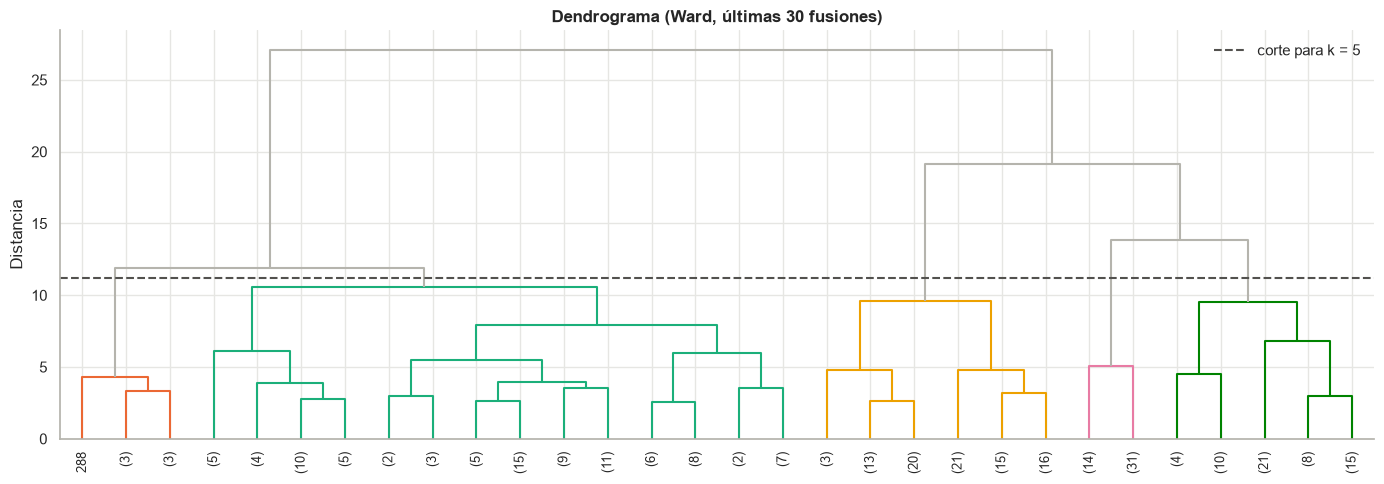

ARI K-Means vs. jerárquico: 0.795
Silueta jerárquico: 0.323 | K-Means: 0.365


Jerárquico,0,1,2,3,4
K-Means,,,,,
0,1,6,85,1,0
1,0,13,0,44,0
2,0,39,3,0,0
3,84,0,0,0,0
4,7,0,0,0,7


In [41]:
Z = linkage(X, method="ward")
corte = (Z[-(K - 1), 2] + Z[-K, 2]) / 2  # altura entre la fusión que deja K grupos y la siguiente
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=corte, above_threshold_color="#b5b4ad",
           leaf_rotation=90, leaf_font_size=9)
plt.axhline(corte, color="#52514e", ls="--", lw=1.5, label=f"corte para k = {K}")
plt.title("Dendrograma (Ward, últimas 30 fusiones)"); plt.ylabel("Distancia"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()

jerarquico = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
ari = adjusted_rand_score(kmeans.labels_, jerarquico)
print(f"ARI K-Means vs. jerárquico: {ari:.3f}")
print(f"Silueta jerárquico: {silhouette_score(X, jerarquico):.3f} | K-Means: {silhouette_score(X, kmeans.labels_):.3f}")
pd.crosstab(activos.loc[X_df.index, "cluster"].values, jerarquico,
            rownames=["K-Means"], colnames=["Jerárquico"])

### 10.7 Interpretación de los clusters

**Elección de k = 5.** La silueta máxima se alcanza en k = 6 (0.369), pero k = 5 queda a menos de 0.01 (0.365) y es más simple de interpretar. Además, Davies-Bouldin es bajo en k = 5 (1.02) y el codo de la inercia se suaviza a partir de ese valor. La partición es muy **estable**: el ARI entre 10 semillas distintas es 0.99. El clustering **jerárquico** de Ward llega a una partición muy parecida (ARI = 0.80). La principal diferencia es que Ward separa a los directivos de mayor rango de los mandos medios.

Los clusters se numeran por tarifa media ascendente:

| Cluster | n | Perfil | Rasgos (promedios) |
|---|---|---|---|
| **0 — Operarios con pocas vacaciones** | 93 | Técnicos de producción (97 % en Producción) | 45 años, tarifa 12.1, nivel 4, **23.5 h de vacaciones**, 0 % asalariados |
| **1 — Operarios jóvenes con muchas vacaciones** | 57 | Técnicos de producción y almacenistas | **41 años** (el grupo más joven), tarifa 12.2, nivel 4, **81.7 h de vacaciones** |
| **2 — Personal operativo veterano** | 42 | Técnicos, compradores (*Buyer*), personal de limpieza | **61 años** (el grupo de mayor edad), tarifa 15.1, nivel ≈ 3.9, 70 h de vacaciones |
| **3 — Profesionales y administrativos** | 84 | Ventas, marketing, especialistas, asistentes | 47 años, **tarifa 24.3**, nivel 2.8, 45 % asalariados, 20 % en Producción |
| **4 — Dirección y gerencia** | 14 | CEO, vicepresidentes, gerentes, ingenieros de diseño | 58 años, **tarifa 55.4**, nivel 1.6, **100 % asalariados**, 25 h de vacaciones |

**Lectura de negocio**

- **Producción no es homogénea.** Sus técnicos ganan casi lo mismo, pero se reparten en tres perfiles (clusters 0, 1 y 2) que se distinguen por **edad** y por **horas de vacaciones acumuladas**. El cluster 1 (jóvenes con más de 80 h acumuladas) y el 2 (veteranos con unas 70 h) acumulan muchas horas sin tomar. Para RR. HH. es un **pasivo laboral** y una señal para planear vacaciones sin afectar los turnos.
- **La compensación sigue la jerarquía.** Los clusters 3 y 4 se separan del resto por tarifa y nivel. El cluster 4 coincide con los atípicos salariales del EAD.
- **Validación con variables que no se usaron.** El tipo de pago (`salariedflag`) y el departamento no entraron al modelo, pero se reproducen: 0 % de asalariados en los clusters operativos, 45 % en el 3 y 100 % en el 4, y la proporción en Producción baja de 97 % a 7 %. Por eso la segmentación tiene sentido de negocio y no es solo un efecto estadístico.
- **La antigüedad no distingue a los grupos** (Kruskal-Wallis, p = 0.31), como ya anticipaba el EAD.

## 11. Conclusiones

**Sobre los datos (EAD)**

1. **Calidad.** La base migrada es consistente: no hay llaves duplicadas ni registros huérfanos, y todo empleado activo tiene una asignación vigente y al menos un salario. Los nulos tienen significado de negocio. Se encontraron tres hallazgos:
   - Los **currículums de candidatos están truncados a 2048 caracteres** por la migración.
   - Hay **2 empleados contratados con 17 años**, dato original de AdventureWorks.
   - Hay **2 empleados de prueba** creados desde el SGRH, que se excluyeron del análisis.
2. **Estructura de la plantilla.** Es una empresa **manufacturera**: Producción concentra el 62 % del personal y casi todo el trabajo de tarde y noche. Predominan el personal **por horas** (82 %), los **hombres** (71 %) y el **nivel jerárquico más bajo** (66 %).
3. **Compensación.** La tarifa es muy **asimétrica** (mediana 14, máximo 125.5) y sus atípicos son directivos reales. La explican el **nivel jerárquico**, el **área** y el **tipo de pago**, no la antigüedad ni el género. No se encontró diferencia significativa por género.
4. **Redundancias.** Hay dos pares de variables que repiten información:
   - `sickleavehours` contra `vacationhours` (r = 0.98).
   - `edad_contratacion` contra `edad` (ρ = 0.99).

   Además, la antigüedad y los historiales salariales y de traslados casi no varían.
5. **Temporalidad.** El 77 % de la plantilla se contrató en 2008–2009, por eso la antigüedad actual es alta y homogénea (15 a 19 años).

**Sobre el análisis de clusters**

6. Con edad, tarifa (en logaritmo), nivel jerárquico y vacaciones, K-Means encuentra **5 perfiles**: tres de operarios de producción (que se diferencian por edad y vacaciones acumuladas), profesionales/administrativos y dirección. La partición es estable entre semillas (ARI 0.99), concuerda con el clustering jerárquico (ARI 0.80) y reproduce variables que no se usaron en el modelo, como el tipo de pago y el departamento.
7. **Hallazgo accionable:** unos 100 operarios (clusters 1 y 2) acumulan en promedio más de 70 horas de vacaciones. Conviene programar esas vacaciones por turnos para reducir el pasivo sin afectar la producción.
8. **Uso en el SGRH:** la segmentación podría agregarse como un nuevo reporte, por ejemplo para revisiones salariales o para el plan de vacaciones de cada perfil.

**Limitaciones**

- AdventureWorks es una base **de muestra**: algunas relaciones son artificiales (como vacaciones e incapacidad).
- La plantilla es pequeña (290 personas) y está muy concentrada en Producción, lo que limita la cantidad de segmentos que se pueden distinguir. La silueta (≈ 0.37) indica una estructura **moderada**, no grupos perfectamente separados.
- Las cifras corresponden a la base al momento de la ejecución. Si se crean más registros desde el SGRH, pueden cambiar ligeramente.